In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os
import random
import re
from datetime import datetime
from datetime import date
from pathlib import Path

In [2]:
timestamp = '2026-03-26_124041' #'2026-03-11_185845'
file = f"/data/icecores/Output//AN/ALHIC/ALHIC2302/FullCoreData/{timestamp}/combinedSums.csv"
combined_df = pd.read_csv(file)

# timestampTransmissiveLayers = '2025-10-22_112959'
# Transmissivefile = f"/data/icecores/Output//AN/ALHIC/ALHIC2302/FullCoreData/{timestampTransmissiveLayers}/combinedSums.csv"
# transmissive_df = pd.read_csv(Transmissivefile)
# transmissive_df['Depth_cm'] = transmissive_df['Depth_cm'] / 100

timestampBubbles = '2026-03-13_212847'
fileBubbles = f"/data/icecores/Output/AN/ALHIC/ALHIC2302/FullCoreData/{timestampBubbles}/combinedBubbles.csv"
bubbles_df = pd.read_csv(fileBubbles)

timestampPCA = '2026-03-25_151255'
filePCA = f"/data/icecores/Output/AN/ALHIC/ALHIC2302/FullCoreData/{timestampPCA}/combinedPCA.csv"
PCA_df = pd.read_csv(filePCA)

now = datetime.now().strftime("%Y-%m-%d_%H%M%S")
output_dir = Path(f"/data/icecores/Output/AN/ALHIC/ALHIC2302/FullCoreData/{now}")
output_dir.mkdir(parents=True, exist_ok=False) 
print("Output Dir: ", output_dir)

Output Dir:  /data/icecores/Output/AN/ALHIC/ALHIC2302/FullCoreData/2026-03-26_141435


In [3]:
from pathlib import Path
from typing import Optional, Dict, List, Tuple
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import ruptures as rpt

def _rolling_median_rows(x: np.ndarray,
                         window_rows: int,
                         min_count: int) -> np.ndarray:
    s = pd.Series(x)
    return s.rolling(window=window_rows, center=True, min_periods=min_count).median().to_numpy()

def plot_stats_by_depth(df: pd.DataFrame,
                        title: str,
                        save: bool = False,
                        save_path: Optional[Path | str] = None,
                        show: bool = True,
                        invert_depth_axis: bool = True,
                        shade_gaps: bool = False,
                        gap_threshold: float = 5.0,
                        # --- PCA options ---
                        show_pca: bool = False,
                        PCA_df: Optional[pd.DataFrame] = None,
                        # --- Change-point detection (PELT) ---
                        do_cpd: bool = False, 
                        # --- Rolling median line (rows-only) ---
                        overlay_median: bool = False,
                        median_window_rows: int = 11,
                        median_min_count: int = 5,
                        # --- Optional bubbles panel (inserted as panel #2) ---
                        bubbles_df: Optional[pd.DataFrame] = None,
                        bubble_col: str = "Normalized_Count",
                        bubble_label: Optional[str] = None
                        ) -> Dict[str, Optional[Path]]:
    """
    Figure with shared Y (Depth), panels left→right:
      1) Sums vs Depth
      2) Bubbles <bubble_col> vs Depth (ONLY if bubbles_df provided)
      3) Medians vs Depth
      4) Means vs Depth
      5+) PC1, PC2 vs Depth (if show_pca=True)

    If overlay_median=True, draws a single red rolling-median line (rows-only window)
    on each panel.
    """
    required = {"Depth_cm", "Sums", "Medians", "Means", "Median_5", "Median_95", "STDev"}
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"DataFrame missing columns: {sorted(missing)}")

    # Clean primary stats DF
    dfx = df.copy()
    for col in ["Depth_cm", "Sums", "Medians", "Means", "Median_5", "Median_95", "STDev"]:
        dfx[col] = pd.to_numeric(dfx[col], errors="coerce")
    dfx['Depth_cm'] = dfx['Depth_cm'] / 100
    dfx = dfx.dropna(subset=["Depth_cm", "Sums", "Medians", "Means", "Median_5", "Median_95", "STDev"]).sort_values("Depth_cm")
    if dfx.empty:
        raise ValueError("No valid rows after cleaning input DataFrame.")

    # Optional bubbles DF
    bdf = None
    if bubbles_df is not None:
        bdf = bubbles_df.copy()
        if "Depth_cm" not in bdf.columns or bubble_col not in bdf.columns:
            raise ValueError(f"bubbles_df must contain 'Depth_cm' and '{bubble_col}'.")
        bdf["Depth_cm"] = pd.to_numeric(bdf["Depth_cm"], errors="coerce")
        bdf['Depth_cm'] = bdf['Depth_cm'] / 100
        bdf[bubble_col] = pd.to_numeric(bdf[bubble_col], errors="coerce")
        # bdf["Bubble_Count"] = bdf['Bubble_Count'] / 25
        bdf = bdf.dropna(subset=["Depth_cm", bubble_col]).sort_values("Depth_cm")
        if bdf.empty:
            print("[warn] bubbles_df is empty after cleaning; skipping bubbles panel.")
            bdf = None
    if bubble_label is None:
        bubble_label = f"{bubble_col} (bubbles)"

    if save:
        save_dir = Path(save_path) if save_path is not None else Path(".")
        save_dir.mkdir(parents=True, exist_ok=True)
    else:
        save_dir = None

    ages = pd.read_csv("/data/icecores/ALHIC2302_Ages.csv")
    ages["Top depth"] = pd.to_numeric(ages["Top depth"], errors="coerce")
    ages["Bottom depth "] = pd.to_numeric(ages["Bottom depth "], errors="coerce")
    ages["Argon age "] = pd.to_numeric(ages["Argon age "], errors="coerce")
    # Drop any rows with missing or infinite depths
    ages = ages.replace([np.inf, -np.inf], np.nan).dropna(subset=["Top depth", "Bottom depth ", "Argon age "])

    # -------- Optional show PCA (external PCA_df) --------
    pc_labels: list[str] = []
    pcs: Optional[np.ndarray] = None
    pca_depths: Optional[np.ndarray] = None

    if show_pca:
        if PCA_df is None:
            print("[warn] show_pca=True but no PCA_df provided; skipping PCA panels.")
        else:
            required_pca_cols = [
                "Depth_cm",
                "PC1", "PC2", "PC3", "PC4", "PC5",
                "PC1_Sums", "PC2_Sums", "PC3_Sums", "PC4_Sums", "PC5_Sums"
            ]

            missing = [c for c in required_pca_cols if c not in PCA_df.columns]
            if missing:
                print(f"[warn] PCA_df missing columns {missing}; skipping PCA panels.")
            else:
                dp = PCA_df.copy()

                # Clean
                dp["Depth_cm"] = pd.to_numeric(dp["Depth_cm"], errors="coerce") / 100
                for col in required_pca_cols[1:]:
                    dp[col] = pd.to_numeric(dp[col], errors="coerce")

                dp = dp.dropna(subset=["Depth_cm", "PC1", "PC2"]).sort_values("Depth_cm")

                if dp.empty:
                    print("[warn] PCA_df empty after cleaning; skipping PCA panels.")
                else:
                    # PCs to plot 
                    pc_cols = ["PC1", "PC2"]

                    pcs = dp[pc_cols].to_numpy()
                    pca_depths = dp["Depth_cm"].to_numpy()

                    # Labels 
                    pc_labels = pc_cols
    
    # # -------- Optional show PCA (uses PCA_Sums & PCA_Medians) --------
    # pc_labels: list[str] = []
    # pcs: Optional[np.ndarray] = None
    # pca_depths: Optional[np.ndarray] = None

    # if show_pca:
    #     pca_cols = ["PCA_Sums", "PCA_Medians"]
    #     missing_p = [c for c in pca_cols if c not in dfx.columns]
    #     if missing_p:
    #         print(f"[warn] show_pca=True but missing columns {missing_p}; skipping PCA panels.")
    #     else:
    #         dp = dfx[["Depth_cm"] + pca_cols].copy()
    #         dp["Depth_cm"] = pd.to_numeric(dp["Depth_cm"], errors="coerce")
    #         for c in pca_cols:
    #             dp[c] = pd.to_numeric(dp[c], errors="coerce")
    #         dp = dp.dropna(subset=pca_cols).sort_values("Depth_cm")
    #         if dp.empty:
    #             print("[warn] PCA columns present but all-NaN after cleaning; skipping PCA panels.")
    #         else:
    #             X = dp[pca_cols].to_numpy(dtype=float)
    #             # z-score
    #             mu = X.mean(axis=0)
    #             sd = X.std(axis=0, ddof=0); sd[sd == 0] = 1.0
    #             Xz = (X - mu) / sd
    #             # SVD PCA
    #             U, S, Vt = np.linalg.svd(Xz, full_matrices=False)
    #             scores = Xz @ Vt.T
    #             k = min(2, scores.shape[1])
    #             pcs = scores[:, :k]
    #             loadings = Vt[:k]
    #             pc_labels = []
                
    #             for i in range(k):
    #                 terms = []
    #                 for feature, weight in zip(pca_cols, loadings[i]):
    #                     terms.append(f"{weight:.2f}·{feature}")
    #                 pc_labels.append(f"PC{i+1}:\n" + " + ".join(terms))
    #             # pc_labels = [f"PC{i+1} (PCA)" for i in range(k)]
    #             pca_depths = dp["Depth_cm"].to_numpy()

    # Layout: Sums, (Bubbles), Medians, Means, (PC1, PC2)
    extra_bubbles = 1 if bdf is not None else 0
    n_panels = 3 + len(pc_labels) + extra_bubbles
    fig_w = 4 * n_panels
    fig_h = 15
    fig, axes = plt.subplots(1, n_panels, figsize=(fig_w, fig_h), sharey=True)
    if n_panels == 1:
        axes = [axes]

    def finish_axis(ax, set_ylabel=False, depths_for_shading: Optional[np.ndarray] = None):
        depths_for_shading = depths_for_shading if depths_for_shading is not None else dfx["Depth_cm"].to_numpy()
        if shade_gaps:
            depths = depths_for_shading
            gaps = np.where(np.diff(depths) > gap_threshold)[0]
            for g in gaps:
                y1, y2 = depths[g], depths[g + 1]
                ax.axhspan(y1, y2, color="gray", alpha=0.15)
        if invert_depth_axis:
            ax.invert_yaxis()
        if set_ylabel:
            ax.set_ylabel("Depth (m)", fontsize=12)

    def overlay_median_line(ax, x_vals: np.ndarray, depths: np.ndarray):
        if not overlay_median:
            return
        med = _rolling_median_rows(
            x_vals.astype(float),
            window_rows=median_window_rows,
            min_count=median_min_count
        )
        mask = ~(np.isnan(med) | np.isnan(depths))
        if np.any(mask):
            ax.scatter(med[mask], depths[mask], c='red', s=.25, label=f"Rolling median window: {median_window_rows}")

    stats_depths = dfx["Depth_cm"].to_numpy()
    panel_idx = 0

     # Panel 2: Bubbles (if provided)
    if bdf is not None:
        ax = axes[panel_idx]; panel_idx += 1
        b_depths = bdf["Depth_cm"].to_numpy()
        b_vals = bdf[bubble_col].to_numpy()
        ax.scatter(b_vals, b_depths, s=6)
        overlay_median_line(ax, b_vals, b_depths)
        for index, row in ages.iterrows():
            top, bottom, age = row["Top depth"], row["Bottom depth "], row["Argon age "]
            # Draw a shaded rectangle for the interval
            ax.axhspan(top, bottom, color="y", alpha=0.3)
             # Label the age in the middle of the interval
            mid_depth = (top + bottom) / 2
            if index % 2 != 1:
                ax.text(ax.get_xlim()[1]*0.85, mid_depth, f"{age} ka",
                    va='center', ha='left', fontsize=9, color='black')
            else:
                ax.text(ax.get_xlim()[1]*0.85, mid_depth, f"{age} ka",
                    va='center', ha='right', fontsize=9, color='black')
        ax.set_title(bubble_label, fontsize=16, fontweight='bold')
        ax.set_xlabel("Bubbles per cm²", fontsize=12)
        ax.invert_yaxis()
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        finish_axis(ax, set_ylabel=True, depths_for_shading=b_depths)

    # Panel 1: Sums
    ax = axes[panel_idx]; panel_idx += 1
    x = dfx["Sums"].to_numpy()
    ax.scatter(x, stats_depths, s=1.5)
    overlay_median_line(ax, x, stats_depths)
    for index, row in ages.iterrows():
        top, bottom, age = row["Top depth"], row["Bottom depth "], row["Argon age "]
        # Draw a shaded rectangle for the interval
        ax.axhspan(top, bottom, color="y", alpha=0.3)
        if bdf is None:
            # Label the age in the middle of the interval
            mid_depth = (top + bottom) / 2
            if index % 2 != 1:
                ax.text(ax.get_xlim()[1]*0.85, mid_depth, f"{age} ka",
                    va='center', ha='left', fontsize=9, color='black')
            else:
                ax.text(ax.get_xlim()[1]*0.85, mid_depth, f"{age} ka",
                    va='center', ha='right', fontsize=9, color='black')
    ax.set_title("Cumulative", fontsize=16, fontweight='bold')
    ax.set_xlabel("Intensity (Digital Number)", fontsize=12)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    if bdf is None:
        finish_axis(ax, set_ylabel=True, depths_for_shading=stats_depths)
    else:
        finish_axis(ax, set_ylabel=False, depths_for_shading=stats_depths)


    # Panel 3: Medians
    ax = axes[panel_idx]; panel_idx += 1
    x = dfx["Medians"].to_numpy()
    x_low = (dfx["Medians"] - dfx["Median_5"]).to_numpy()
    x_high = (dfx["Median_95"] - dfx["Medians"]).to_numpy()
    # Gray 5–95% error bars
    ax.errorbar(
        x,
        stats_depths,
        xerr=[x_low, x_high],
        fmt='.',
        markersize=5,
        ecolor="lightgray",
        elinewidth=2,
        capsize=0,
        color="tab:blue",
        label="Median (5–95%)"
    )
    ax.scatter(x, stats_depths, s=1.5)
    overlay_median_line(ax, x, stats_depths)
    for index, row in ages.iterrows():
        top, bottom, age = row["Top depth"], row["Bottom depth "], row["Argon age "]
        # Draw a shaded rectangle for the interval
        ax.axhspan(top, bottom, color="y", alpha=0.3)
    ax.set_title("Median", fontsize=16, fontweight='bold')
    ax.set_xlabel("Intensity (Digital Number)", fontsize=12)
    # ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    finish_axis(ax, set_ylabel=False, depths_for_shading=stats_depths)

    # Panel 4: Means
    ax = axes[panel_idx]; panel_idx += 1
    x = dfx["Means"].to_numpy()
    std = (dfx["STDev"]).to_numpy()
    # Gray 5–95% error bars
    ax.errorbar(
        x,
        stats_depths,
        xerr=std,
        fmt='.',
        markersize=5,
        ecolor="lightgray",
        elinewidth=2,
        capsize=0,
        color="tab:blue",
        label="Mean (±1σ)"
    )
    ax.scatter(x, stats_depths, s=1.5)
    overlay_median_line(ax, x, stats_depths)
    for index, row in ages.iterrows():
        top, bottom, age = row["Top depth"], row["Bottom depth "], row["Argon age "]
        # Draw a shaded rectangle for the interval
        ax.axhspan(top, bottom, color="y", alpha=0.3)
    ax.set_title("Mean", fontsize=16, fontweight='bold')
    ax.set_xlabel("Intensity (Digital Number)", fontsize=12)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    finish_axis(ax, set_ylabel=False, depths_for_shading=stats_depths)

    # Panels 5+: PC1, PC2 (if enabled)
    for j, lbl in enumerate(pc_labels):
        ax = axes[panel_idx]; panel_idx += 1
        ax.set_xscale('log')
        x = pcs[:, j]
        ax.scatter(x, pca_depths, s=1.5)
        overlay_median_line(ax, x, pca_depths)
        # for index, row in ages.iterrows():
        #     top, bottom, age = row["Top depth"], row["Bottom depth "], row["Argon age "]
        #     # Draw a shaded rectangle for the interval
        #     ax.axhspan(top, bottom, color="y", alpha=0.3)
        ax.set_title(lbl, fontsize=16, fontweight='bold')
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        finish_axis(ax, set_ylabel=False, depths_for_shading=pca_depths)

    # Title & save/show
    handles = []
    labels = []
    
    for ax in fig.axes:
        h, l = ax.get_legend_handles_labels()
        handles.extend(h)
        labels.extend(l)
    
    unique = dict(zip(labels, handles))  # label → handle
    
    fig.legend(
        unique.values(),
        unique.keys(),
        loc="upper center",
        bbox_to_anchor=(.5, -0.02),
        ncols=3,
        fontsize=14
    )
    fig.suptitle(title, fontsize=18, fontweight='bold')
    fig.tight_layout()
    fig.subplots_adjust(top=.9)

    out_path = None
    if save:
        parts = ["stats"]
        if bdf is not None: parts.append("bubbles_p2")
        if show_pca and len(pc_labels) > 0: parts.append("pca")
        if do_cpd and len(cpd_depths) > 0: parts.append("cpd")
        fname = "stats_by_depth_" + "_".join(parts)
        if shade_gaps:
            fname += "_shaded"
        if overlay_median:
            fname += f"_rollmed_rows{median_window_rows}"
        out_path = (save_dir / f"{fname}.png") if save_dir is not None else None
        fig.savefig(out_path, dpi=300, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return {"stats_and_pca_by_depth": out_path}

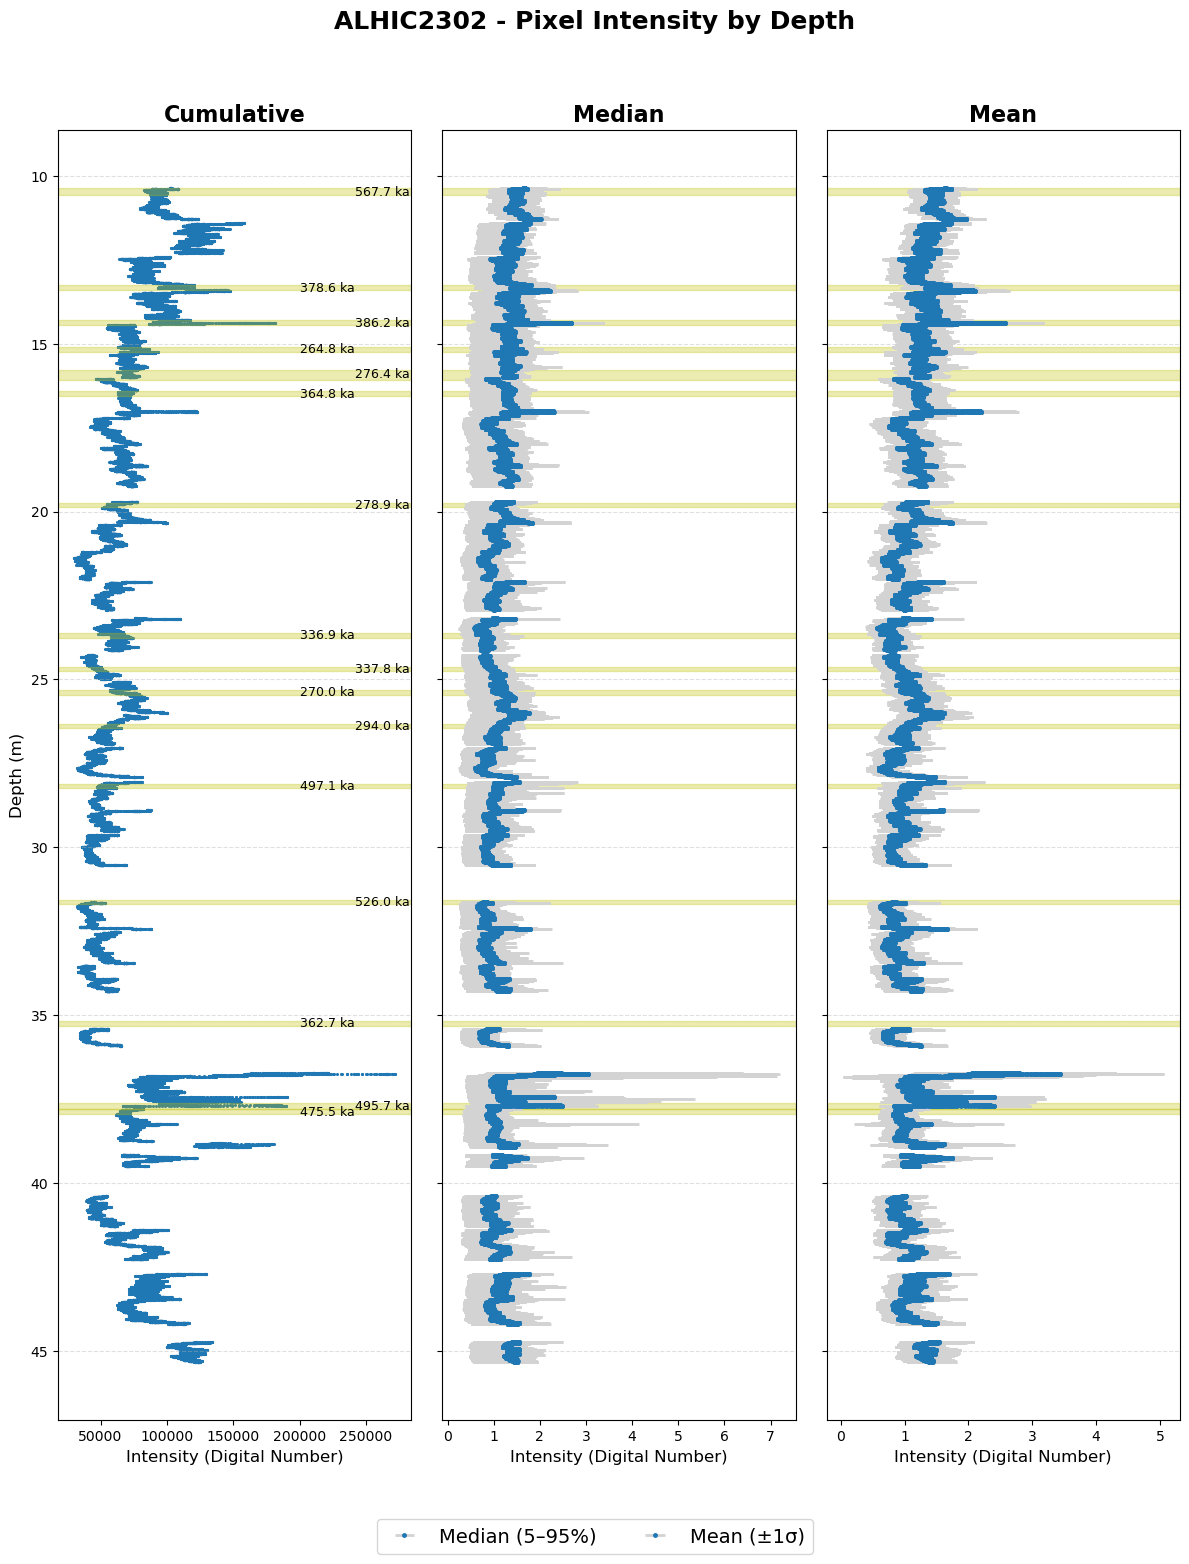

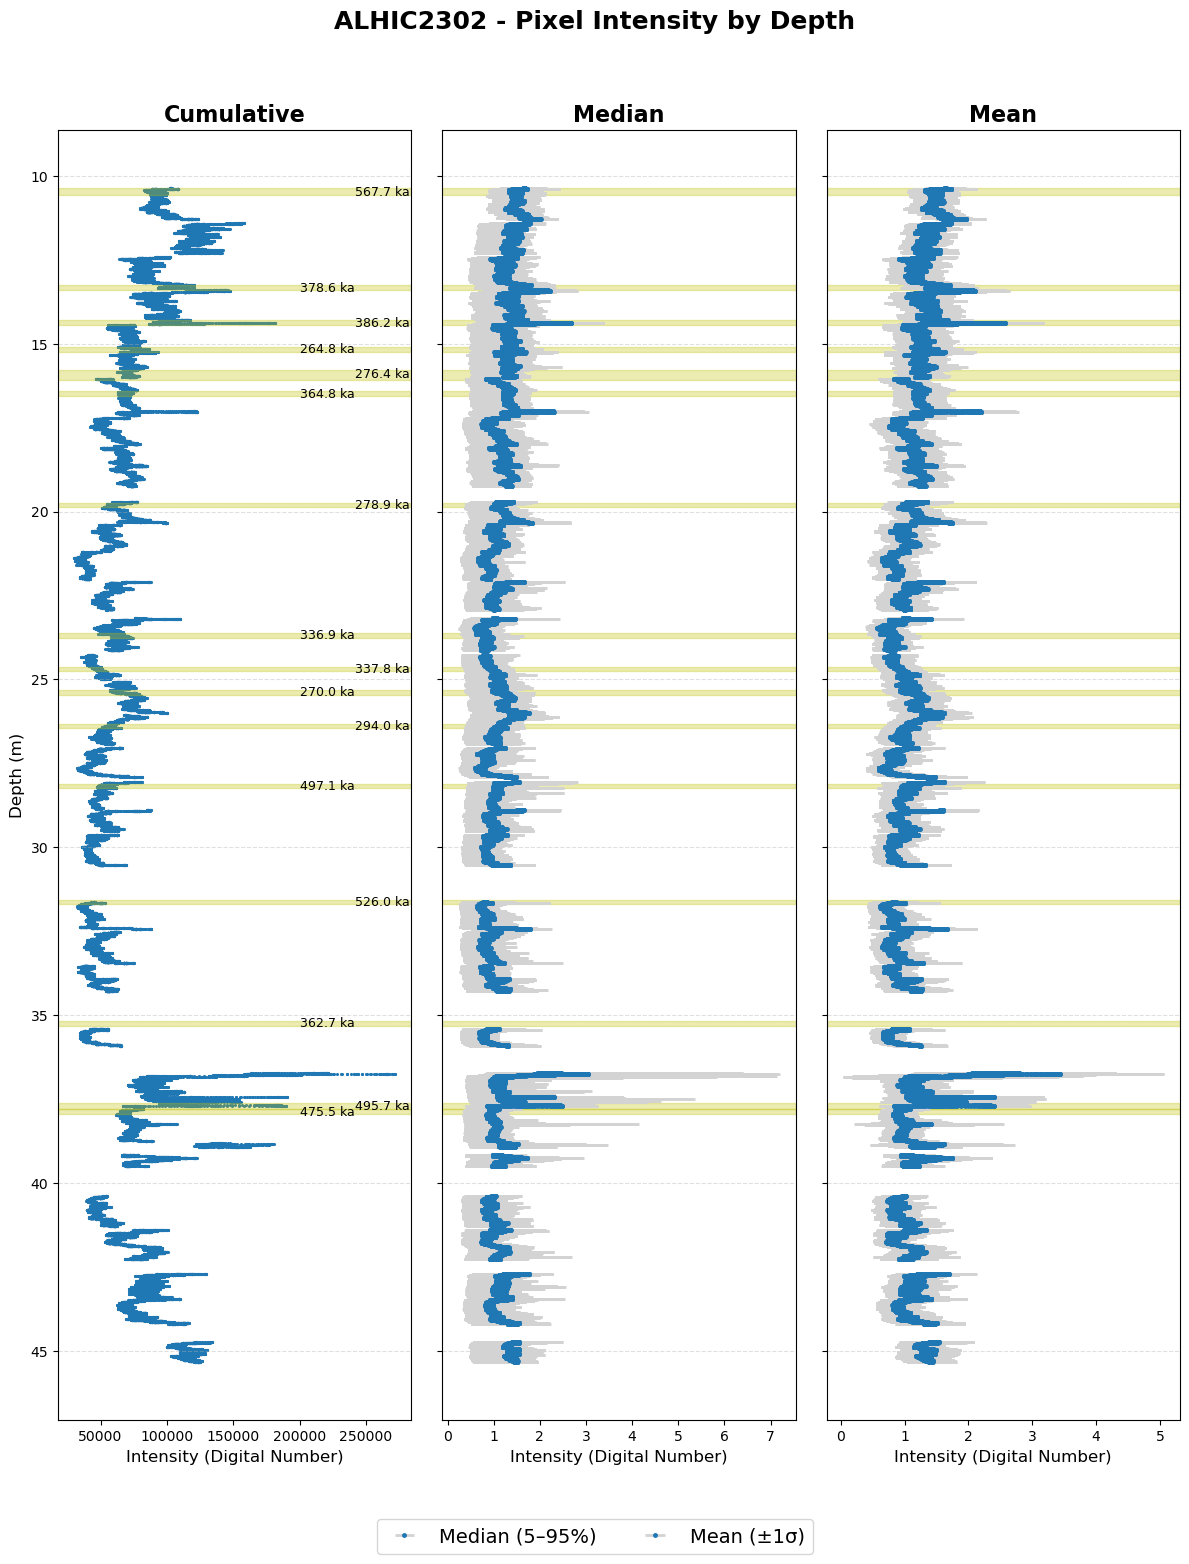

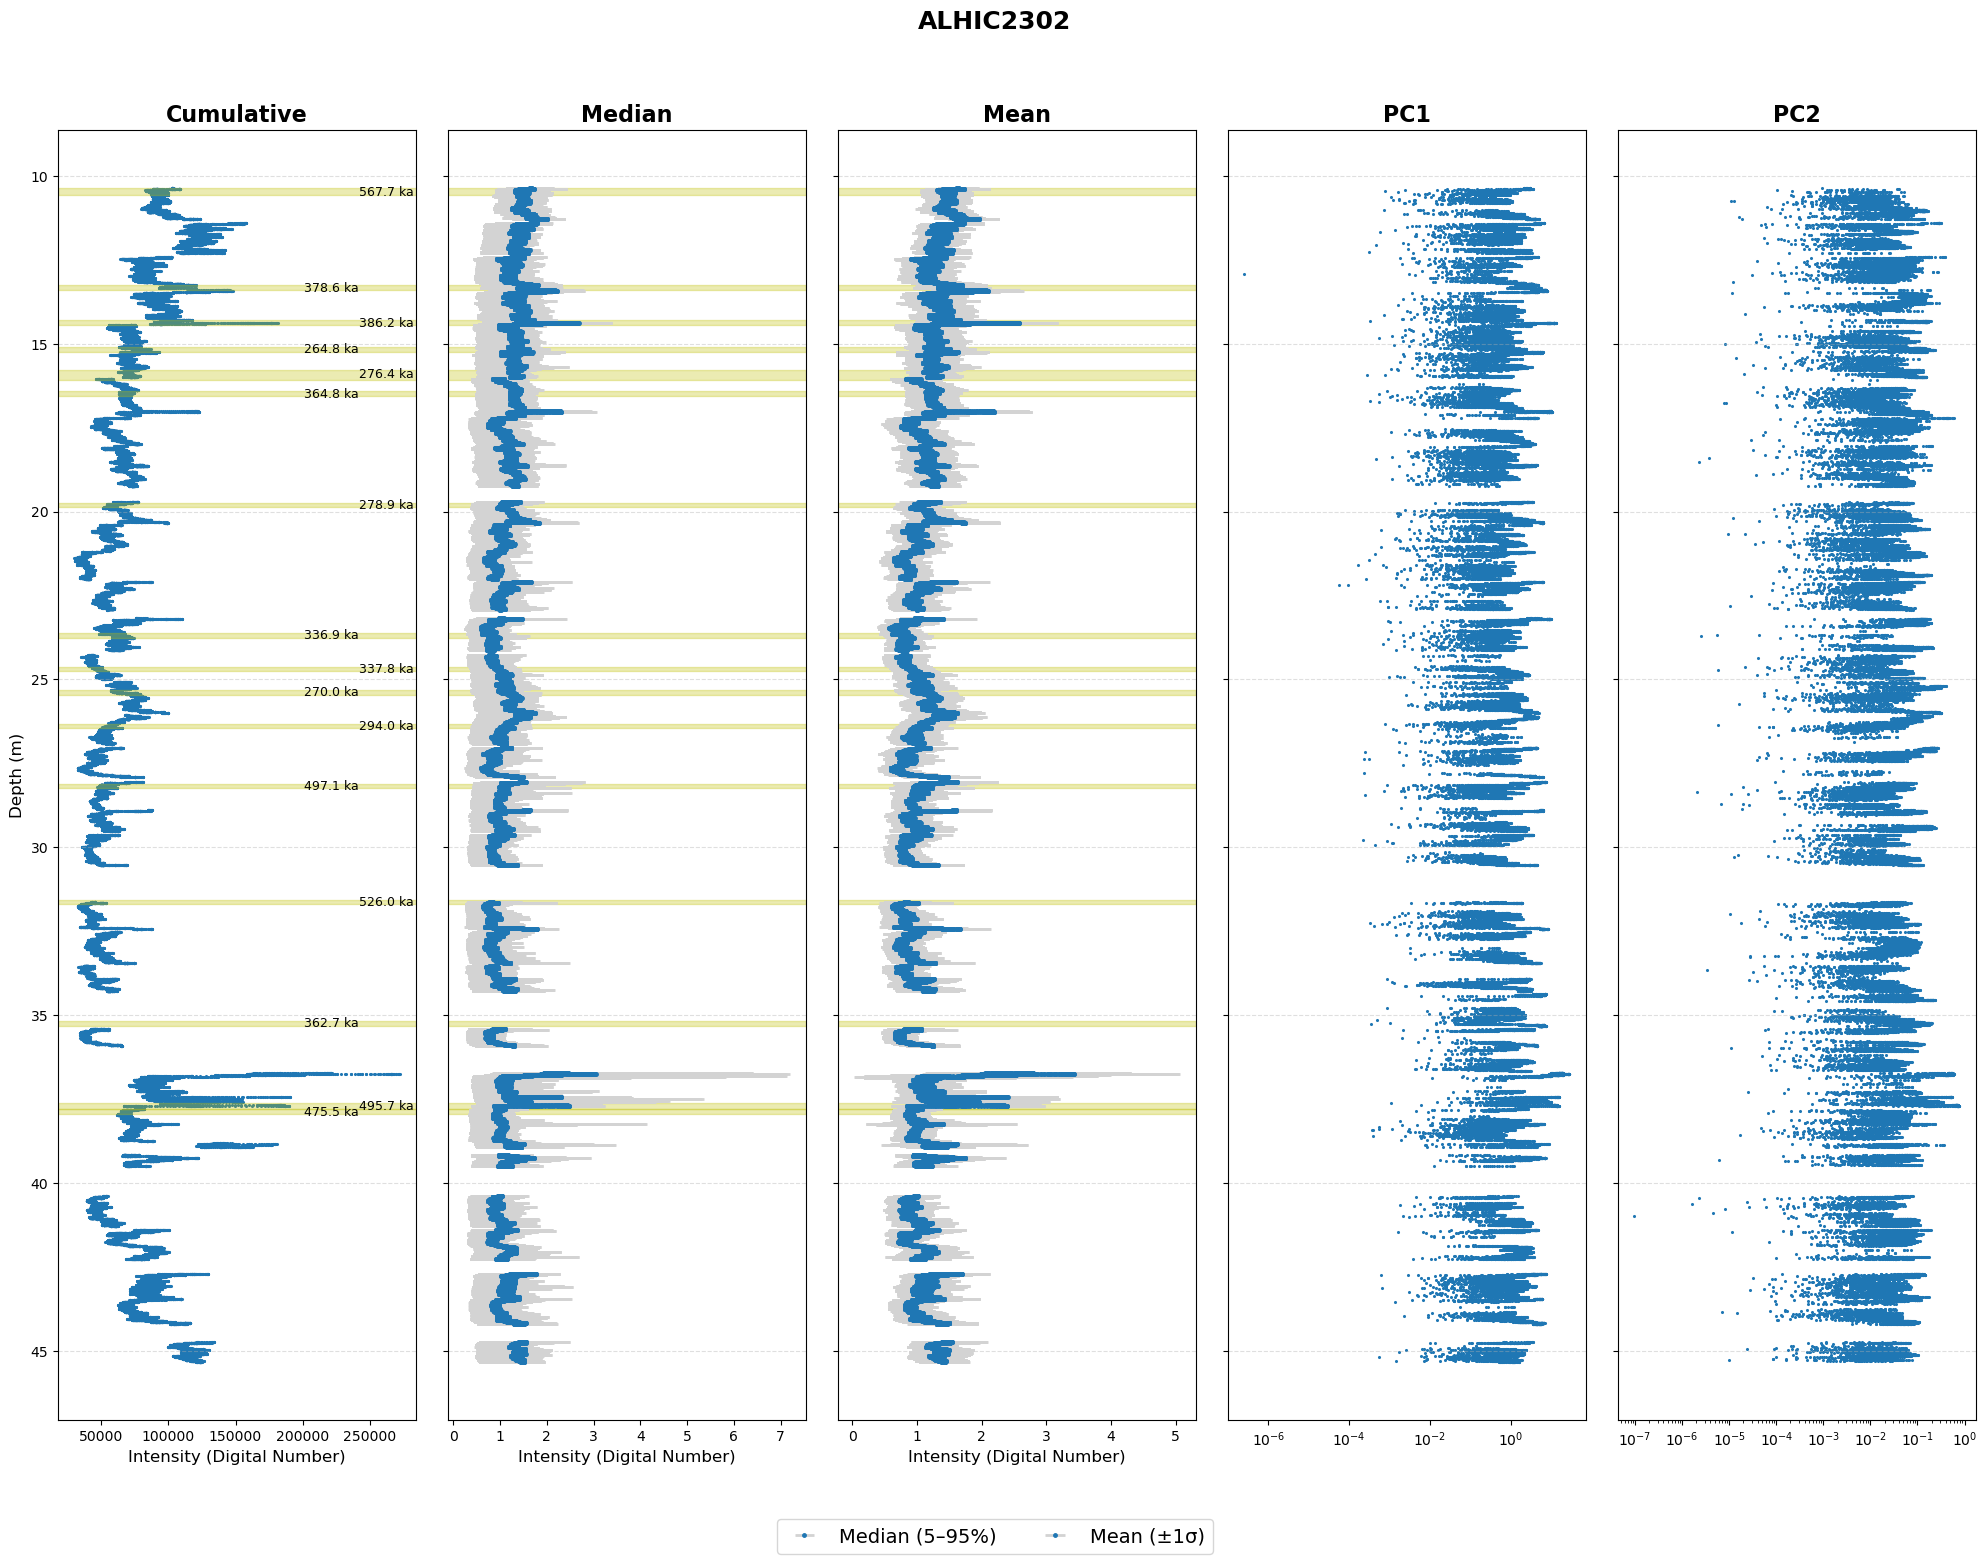

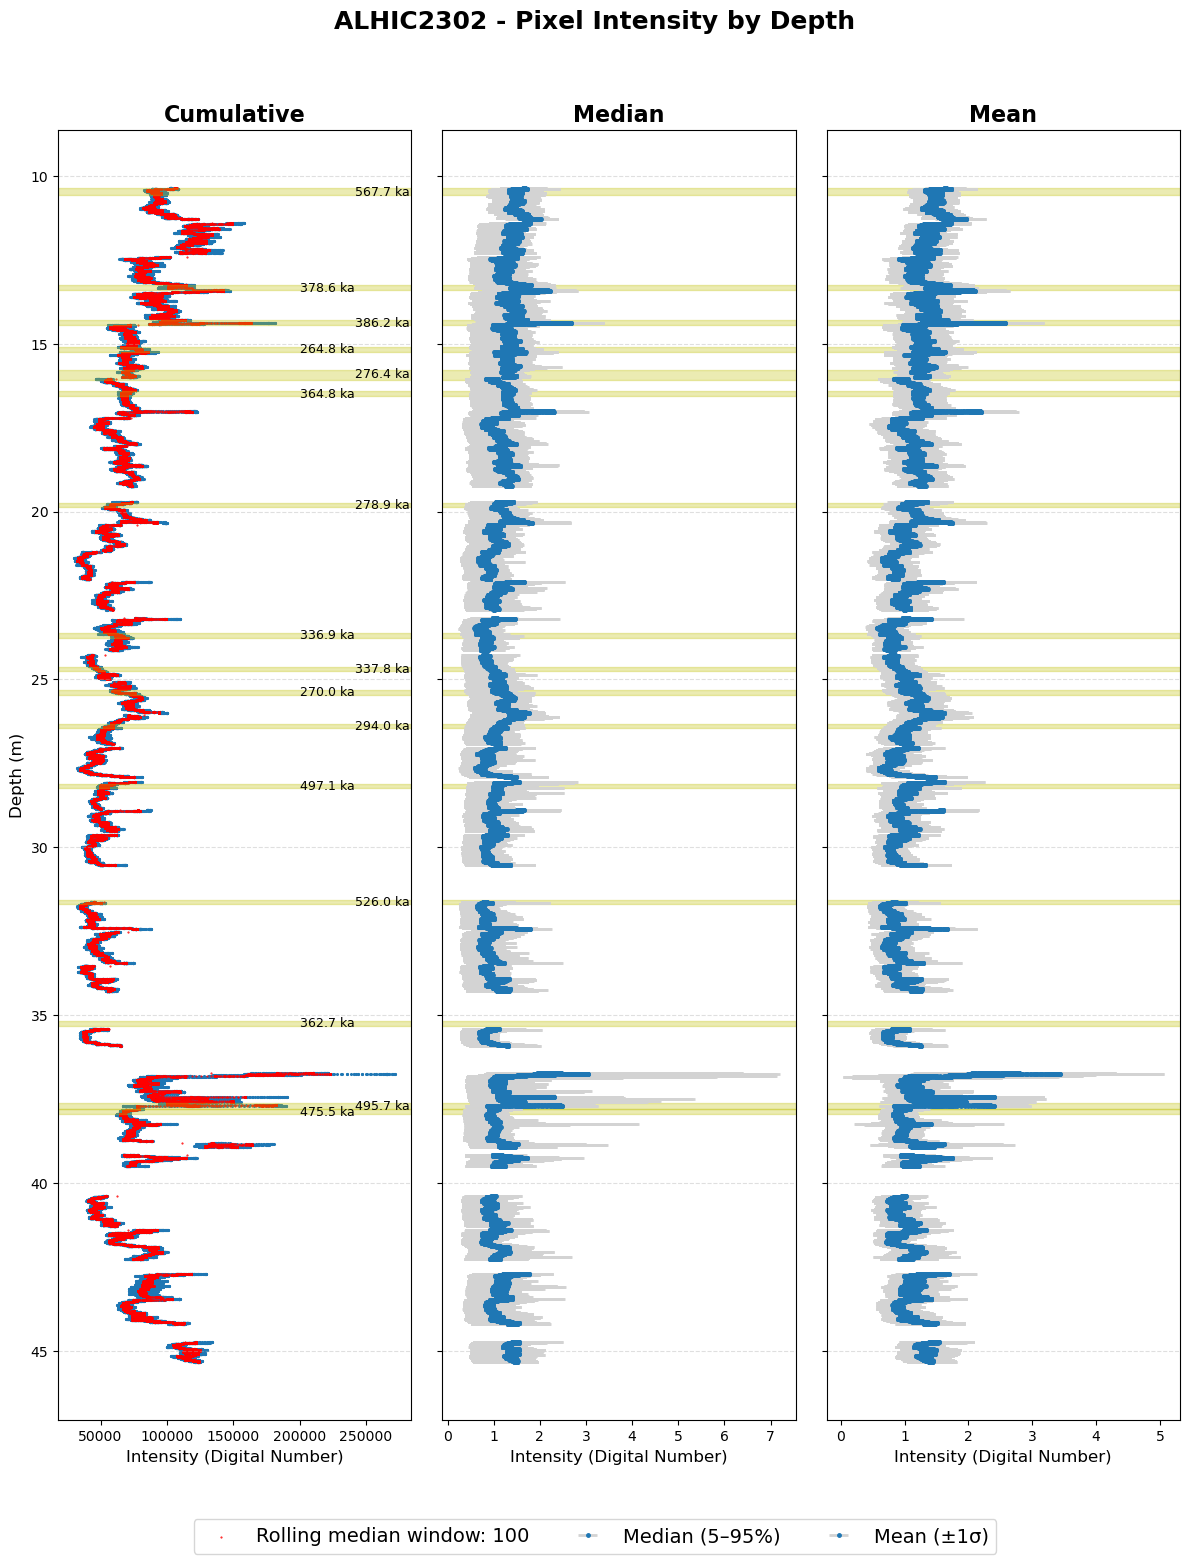

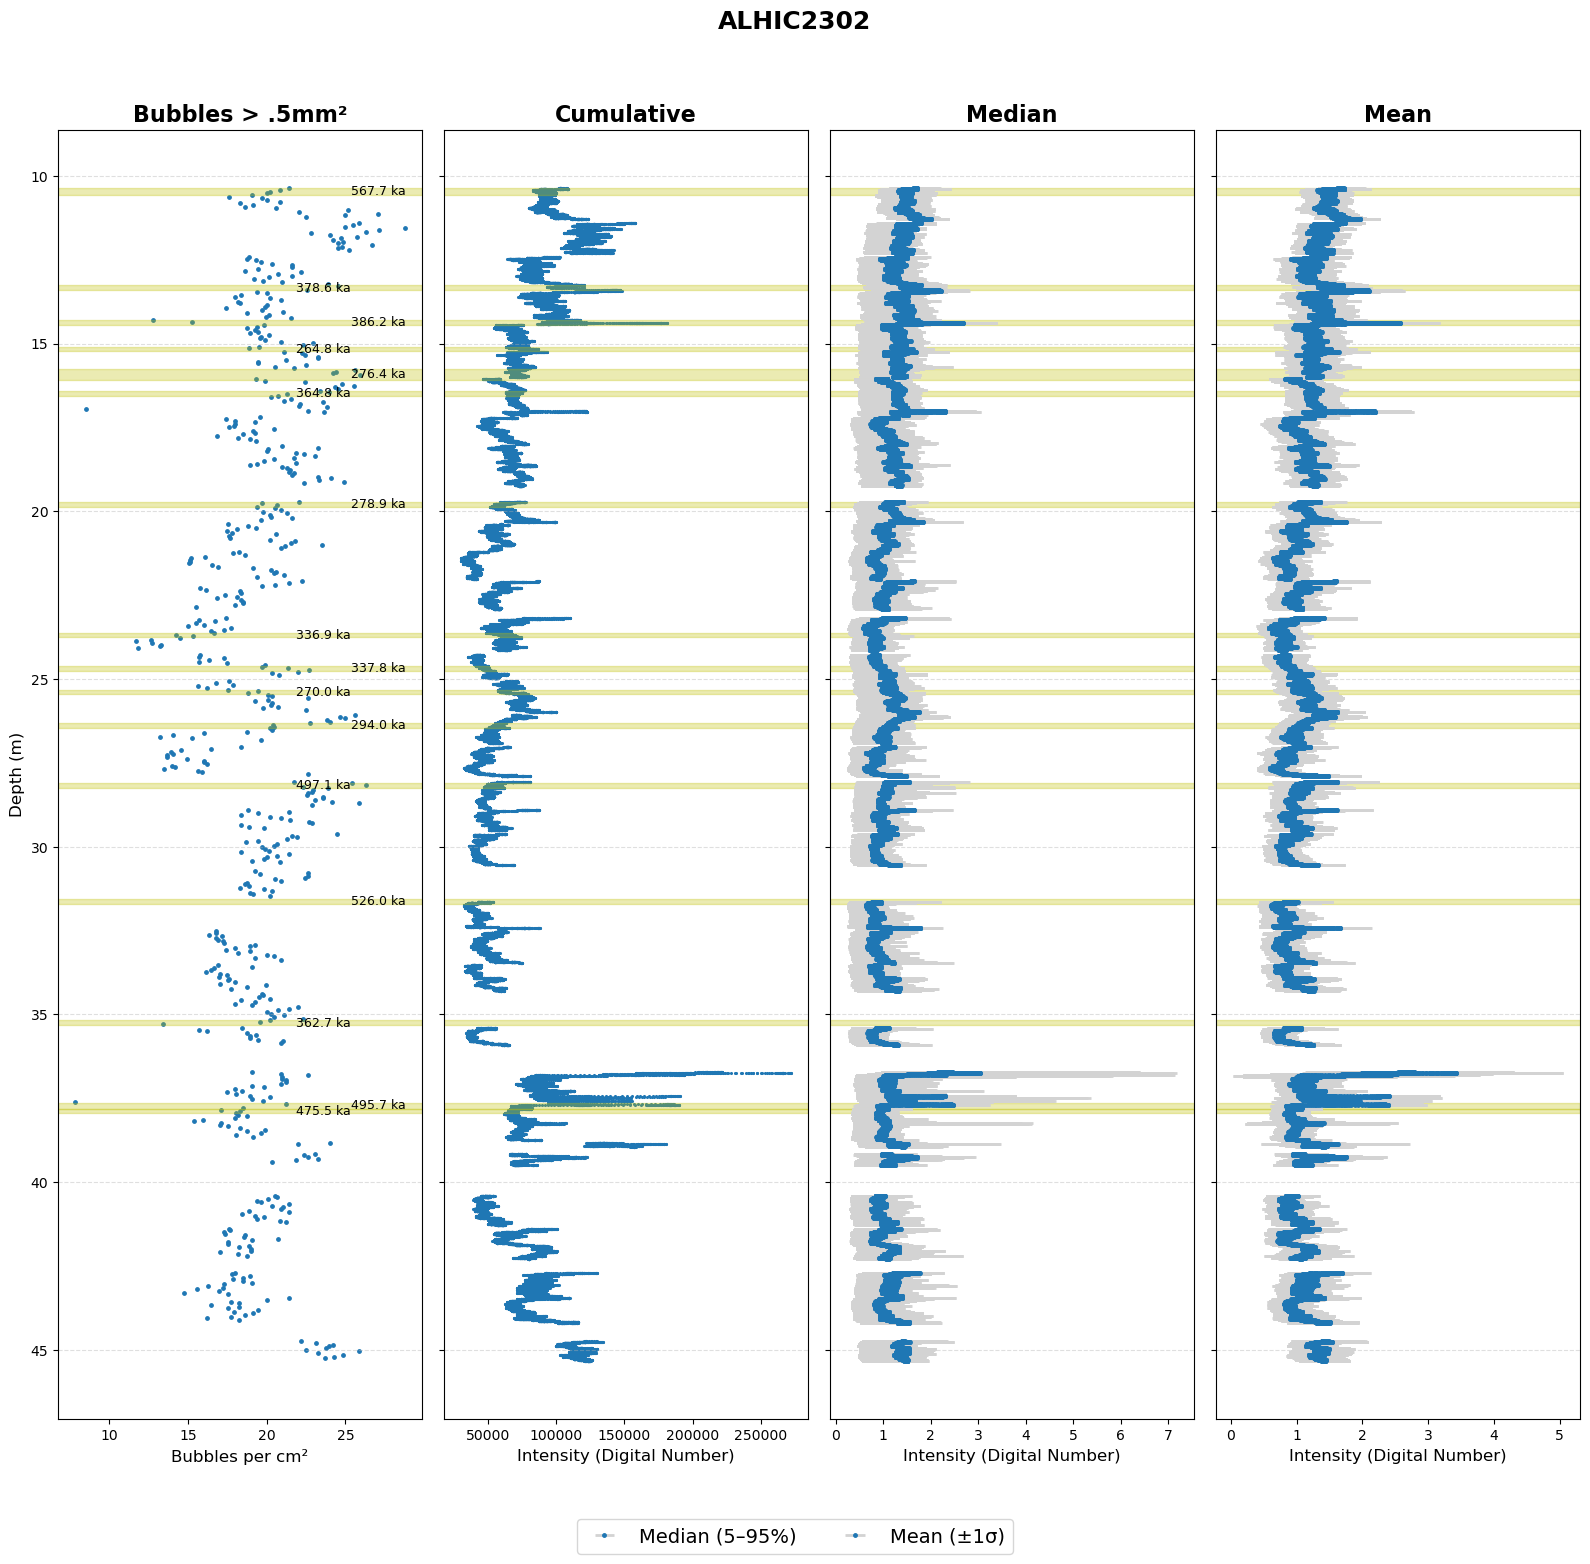

Saved plot files:
stats_and_pca_by_depth: /data/icecores/Output/AN/ALHIC/ALHIC2302/FullCoreData/2026-03-26_141435/stats_by_depth_stats_shaded.png


In [4]:
def smooth_outliers_rolling(df: pd.DataFrame, column: str, window: int = 5, threshold: float = 3.0) -> pd.Series:
    series = df[column]
    rolling_median = series.rolling(window=window, center=True).median()
    
    # Calculate deviation from rolling median
    deviation = (series - rolling_median).abs()
    mad = deviation.rolling(window=window, center=True).median()  # Median Absolute Deviation
    
    # Flag outliers: values farther than threshold * MAD from the rolling median
    outliers = deviation > (threshold * mad)
    
    if outliers.any():
        print(f"\nFixing outliers in '{column}' using rolling median (window={window}, threshold={threshold}):")
        #print(df.loc[outliers, ["Depth_cm", column]].to_string(index=False))
    
    # Replace outliers with rolling median values
    fixed_series = series.copy()
    fixed_series[outliers] = rolling_median[outliers]
    
    return fixed_series


# bubbles_df["Bubble_Count"] = smooth_outliers_rolling(bubbles_df, "Bubble_Count", window=3, threshold=5.0)
# plt.figure(figsize=(5, 10))
# plt.scatter(bubbles_df["Bubble_Count"], bubbles_df["Depth_cm"])
# plt.xlabel("Bubbles in 5x5cm")
# plt.ylabel("Depth (cm)", fontweight='bold')
# plt.title(f"Bubble Count in 5x5cm vs. Depth")
# plt.gca().invert_yaxis()
# plt.grid(True)
# plt.tight_layout()
# plt.savefig(f"{output_dir}/Bubble_CountGraph.png", dpi=300, bbox_inches='tight')
# plt.show()

results = plot_stats_by_depth(
    combined_df,
    title = "ALHIC2302 - Pixel Intensity by Depth",
    save=True,
    save_path=output_dir,
    show=True,
    invert_depth_axis=True,
    shade_gaps=False,
    gap_threshold=2.0
)

# With Gaps Shaded
results = plot_stats_by_depth(
    combined_df,
    title = "ALHIC2302 - Pixel Intensity by Depth",
    save=True,
    save_path=output_dir,
    show=True,
    invert_depth_axis=True,
    shade_gaps=True,
    gap_threshold=2.0
)

# With PCA
out = plot_stats_by_depth(
    combined_df,
    title="ALHIC2302",
    show=True,
    save=True,
    save_path="output_dir",
    # PCA
    show_pca=True,
    PCA_df=PCA_df,
    shade_gaps=False
    # bubbles
    # bubbles_df=bubble_df,
    # bubble_col="Normalized_Count",
    # bubble_label="Bubbles > .5mm²"

)

plot_stats_by_depth(
    combined_df,
    title = "ALHIC2302 - Pixel Intensity by Depth",
    save=True, save_path=output_dir,
    show=True,
    show_pca=False,                    # optional PCA panels
    overlay_median=True,             # <-- single red line
    median_window_rows=100,          # centered window size
    median_min_count=7               # require at least this many points in-window
)

result_paths = plot_stats_by_depth(
    combined_df,
    title = "ALHIC2302",
    save=True, save_path=output_dir,
    show=True,
    show_pca=False,                 # optional PC panels
    overlay_median=False,
    bubbles_df=bubbles_df,        # <-- adds panel #2
    bubble_col="Bubble_Count",
    bubble_label="Bubbles > .5mm²"
)



print("Saved plot files:")
for name, path in results.items():
    print(f"{name}: {path}")

In [5]:
from pathlib import Path
from typing import Optional, Dict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_residual_anomalies(df: pd.DataFrame,
                            title: str,
                            save: bool = False,
                            save_path: Optional[Path | str] = None,
                            show: bool = True,
                            invert_depth_axis: bool = True,
                            window_rows: int = 11,
                            min_count: int = 5
                            ) -> Dict[str, Optional[Path]]:
    """
    Figure with shared Y (Depth), panels left→right:
      1) Anomalous residuals for Sums vs Depth
      2) Anomalous residuals for Medians vs Depth
      3) Anomalous residuals for Means vs Depth

    Residuals are computed as rolling_mean - original_value.
    Negative residuals are set to NaN.
    Anomalous residuals are those >= mean_residual + std_residual.
    """
    required = {"Depth_cm", "Sums", "Medians", "Means"}
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"DataFrame missing columns: {sorted(missing)}")

    # Clean DF
    dfx = df.copy()
    for col in ["Depth_cm", "Sums", "Medians", "Means", "PCA_Sums"]:
        dfx[col] = pd.to_numeric(dfx[col], errors="coerce")
    dfx = dfx.dropna(subset=["Depth_cm", "Sums", "Medians", "Means", "PCA_Sums"]).sort_values("Depth_cm")
    if dfx.empty:
        raise ValueError("No valid rows after cleaning input DataFrame.")

    if save:
        save_dir = Path(save_path) if save_path is not None else Path(".")
        save_dir.mkdir(parents=True, exist_ok=True)
    else:
        save_dir = None

    # Layout: Sums residuals, Medians residuals, Means residuals
    n_panels = 4
    fig_w = 4 * n_panels
    fig_h = 15
    fig, axes = plt.subplots(1, n_panels, figsize=(fig_w, fig_h), sharey=True)
    if n_panels == 1:
        axes = [axes]

    def finish_axis(ax, set_ylabel=False):
        if invert_depth_axis:
            ax.invert_yaxis()
        if set_ylabel:
            ax.set_ylabel("Depth (cm)")

    depths = dfx["Depth_cm"].to_numpy()
    stats = ["Sums", "Medians", "Means", "PCA_Sums"]
    titles = ["Sums", "Medians", "Means", "PCA1"]
    panel_idx = 0

    for stat, tlabel in zip(stats, titles):
        ax = axes[panel_idx]
        panel_idx += 1
        original = dfx[stat].to_numpy()
        s = pd.Series(original)
        rolling_median = s.rolling(window=window_rows, center=True, min_periods=min_count).median().to_numpy()
        residuals = original - rolling_median
        residuals[residuals < 0] = np.nan
        if np.all(np.isnan(residuals)):
            ax.text(0.5, 0.5, "No positive residuals", ha="center", va="center")
        else:
            med_res = np.nanmedian(residuals)
            mad_res = np.nanmedian(np.abs(residuals - med_res))
            
            anomalous_mask = residuals >= (med_res + mad_res)
            if np.any(anomalous_mask):
                ax.scatter(residuals[anomalous_mask], depths[anomalous_mask], s=1.5)
            else:
                ax.text(0.5, 0.5, "No anomalous residuals", ha="center", va="center")
        ax.set_title(f"Anomalous Residuals ({tlabel})")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        finish_axis(ax, set_ylabel=(panel_idx == 1))

    # Title & save/show
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    ax.invert_yaxis()

    if save:
        fname = "residual_anomalies"
        fname += f"_window{window_rows}"
        out_path = (save_dir / f"{fname}.png") if save_dir is not None else None
        fig.savefig(out_path, dpi=300, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return {"residual_anomalies": out_path}

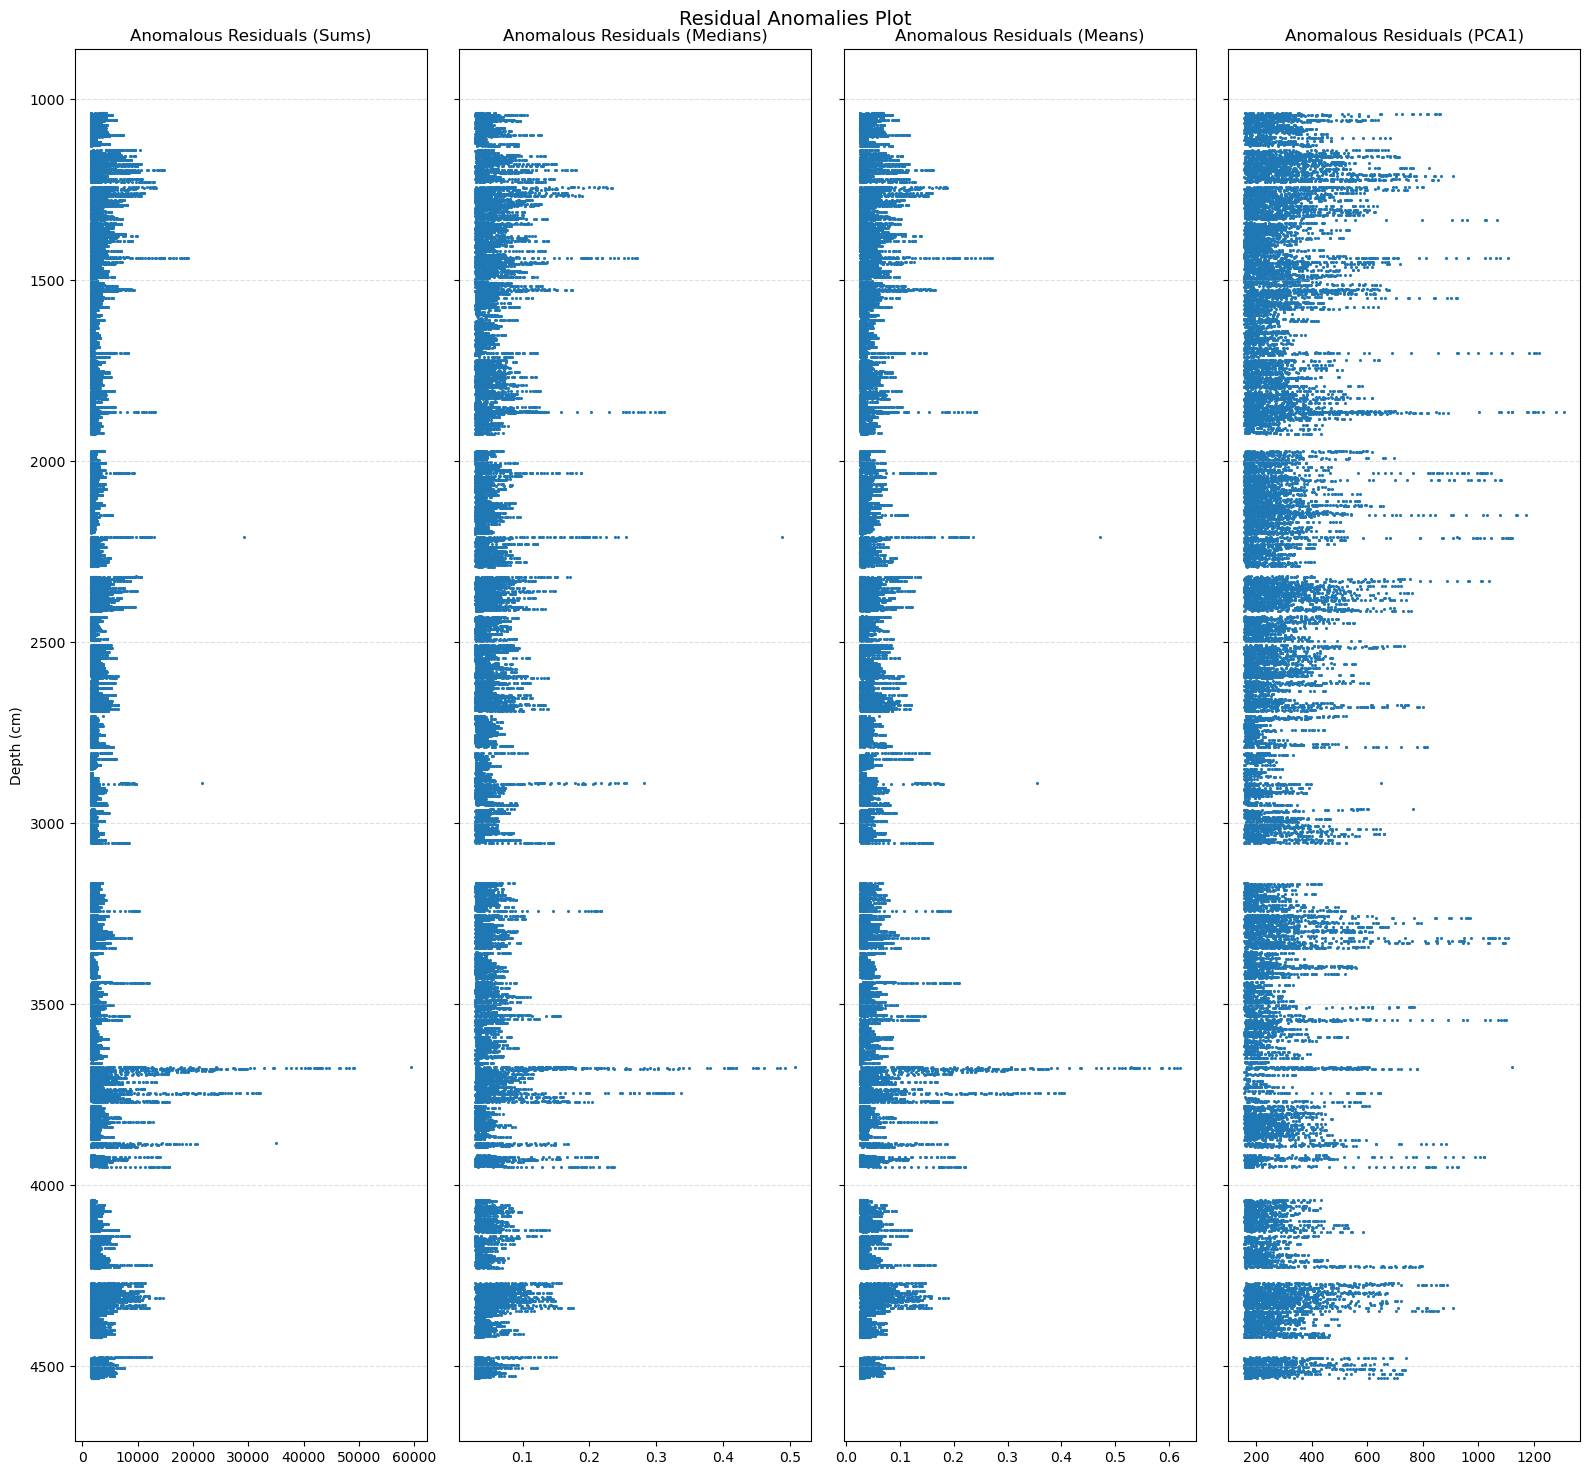

In [6]:
result = plot_residual_anomalies(
    df=combined_df,
    title="Residual Anomalies Plot",
    save=True,
    save_path=output_dir,
    show=True,
    invert_depth_axis=True,
    window_rows=100,
    min_count=5
)

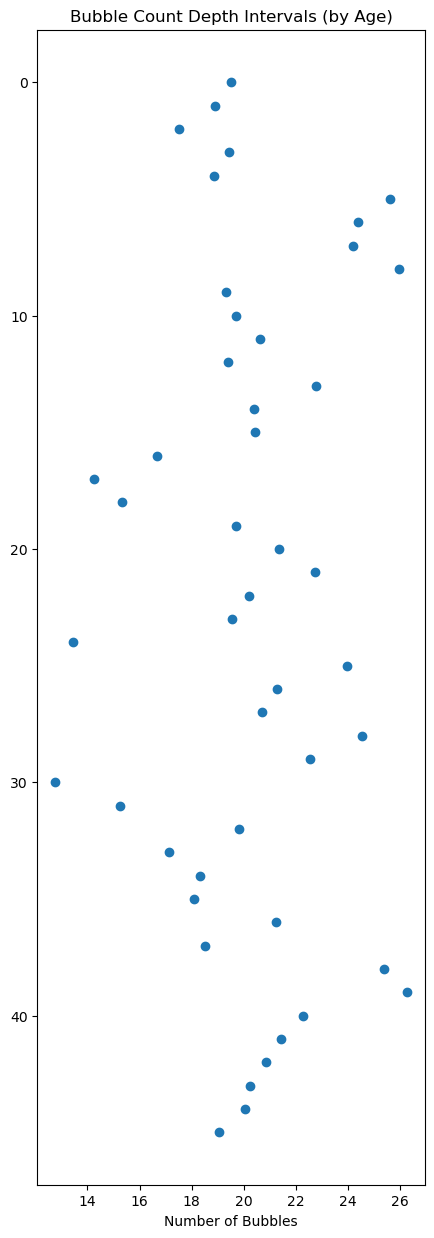

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Clean primary stats DF
dfx = bubbles_df.copy()
for col in ["Depth_cm", "Bubble_Count"]:
    dfx[col] = pd.to_numeric(dfx[col], errors="coerce")
dfx['Depth_cm'] = dfx['Depth_cm'] / 100

# Define intervals (start, end)
intervals = [
    (15.09, 15.23),
    (25.32, 25.46),
    (15.77, 16.07),
    (19.73, 19.87),
    (26.32, 26.46),
    (23.62, 23.76),
    (24.62, 24.76),
    (35.18, 35.32),
    (16.42, 16.56),
    (13.26, 13.41),
    (14.3, 14.45),
    (37.81, 37.95),
    (37.63, 37.81),
    (28.1, 28.24),
    (31.56, 31.7),
    (10.37, 10.57)
]

# Extract intervals (can be out of order)
segments = [
    dfx[(dfx["Depth_cm"] >= start) & (dfx["Depth_cm"] <= end)]
    for start, end in intervals
]

# Combine selected intervals (in this order)
subset = pd.concat(segments, ignore_index=True)

# Plot
plt.figure(figsize=(5,15))
plt.scatter(subset["Bubble_Count"], subset.index)
plt.gca().invert_yaxis() 
plt.xlabel("Number of Bubbles")
plt.title("Bubble Count Depth Intervals (by Age)")
out_path = (output_dir / f"BubbleCountByAge.png")
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

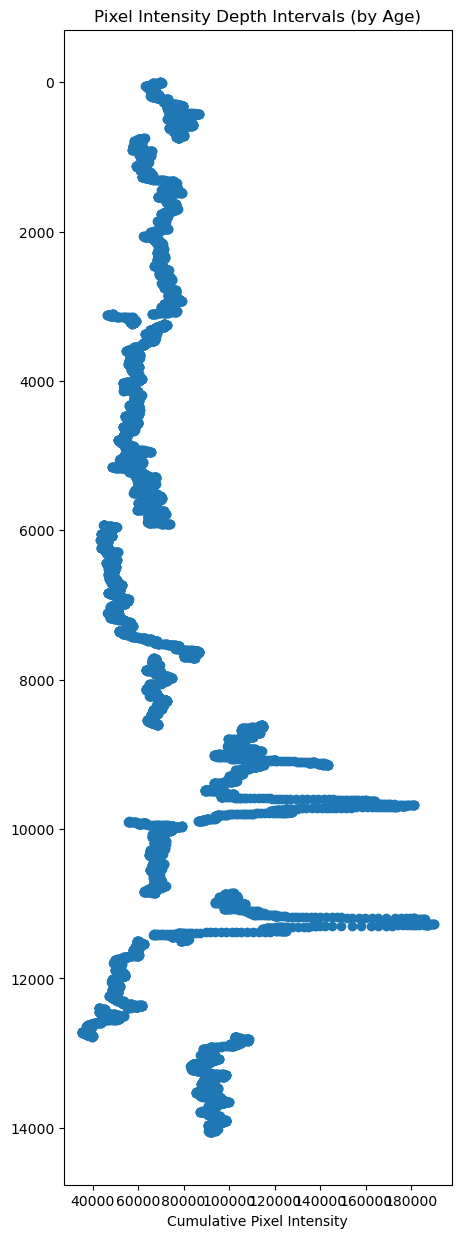

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Clean primary stats DF
dfx = combined_df.copy()
for col in ["Depth_cm", "Sums", "Medians", "Means"]:
    dfx[col] = pd.to_numeric(dfx[col], errors="coerce")
dfx['Depth_cm'] = dfx['Depth_cm'] / 100

# Define intervals (start, end)
intervals = [
    (15.09, 15.23),
    (25.32, 25.46),
    (15.77, 16.07),
    (19.73, 19.87),
    (26.32, 26.46),
    (23.62, 23.76),
    (24.62, 24.76),
    (35.18, 35.32),
    (16.42, 16.56),
    (13.26, 13.41),
    (14.3, 14.45),
    (37.81, 37.95),
    (37.63, 37.81),
    (28.1, 28.24),
    (31.56, 31.7),
    (10.37, 10.57)
]

# Extract intervals (can be out of order)
segments = [
    dfx[(dfx["Depth_cm"] >= start) & (dfx["Depth_cm"] <= end)]
    for start, end in intervals
]

# Combine selected intervals (in this order)
subset = pd.concat(segments, ignore_index=True)

# Plot
plt.figure(figsize=(5,15))
plt.scatter(subset["Sums"], subset.index)
plt.gca().invert_yaxis()
plt.xlabel("Cumulative Pixel Intensity")
plt.title("Pixel Intensity Depth Intervals (by Age)")
out_path = (output_dir / f"PxIntensityByAge.png")
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_59825/147827186.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Depth_cm'] = df['Depth_cm'].values / 100


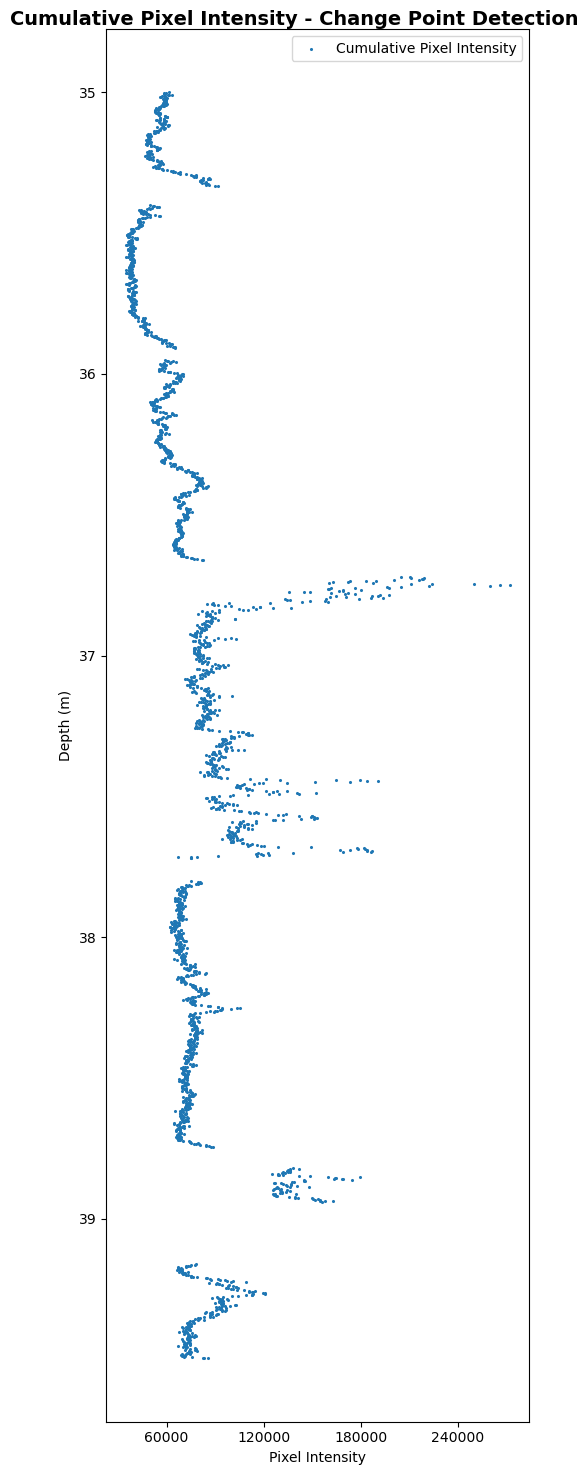

In [9]:
import numpy as np
import pandas as pd
import ruptures as rpt
import matplotlib.pyplot as plt

df = combined_df
df = df[(df["Depth_cm"] >= 3500) & (df["Depth_cm"] <= 4000)]

# Extract the signal (must be a NumPy array)
signal = df['Sums'].iloc[::10].values  # 1D array for univariate

# Initialize PELT with chosen model
model = "rbf"  # Change as needed: "l1", "rbf", etc.
algo = rpt.Pelt(model=model, min_size=100, jump=100).fit(signal)

# Set penalty (adjust based on data size and desired sensitivity)
n = len(signal)
pen = 15 * np.log(n)  # Starting suggestion; tune up/down

# Detect change points
# change_points = algo.predict(pen=pen)

# Print results (indices in the array/DataFrame)
# print("Detected change points (indices):", change_points[:-1])  # Exclude the last (end of signal)
cp = []
# for i in change_points[:-1]:
#     cp.append(df.loc[i, "Depth_cm"])
# print("Detected change points (depth):", cp)

# Or custom plot with 'Depth' on y-axis (assuming 'Depth' increases downward)
if 'Depth_cm' in df.columns:
    fig, ax = plt.subplots(figsize=(5, 15))
    df['Depth_cm'] = df['Depth_cm'].values / 100
    depth = df['Depth_cm'].iloc[::10].values
    ax.scatter(signal, depth, label='Cumulative Pixel Intensity', s=1.5)  # x='Sums', y='Depth'
    # for cp in change_points[:-1]:
    #     ax.axhline(y=depth[cp], color='r', linestyle='--', label='Change Point' if cp == change_points[0] else None)
    ax.invert_yaxis()  # If depth increases downward
    ax.set_xlabel('Pixel Intensity')
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.set_ylabel('Depth (m)')
    ax.legend()

    # Title & save/show
    fig.suptitle("Cumulative Pixel Intensity - Change Point Detection", fontsize=14, fontweight='bold')
    fig.tight_layout()

    out_path = output_dir
    fname = "cpd"
    out_path = (out_path / f"{fname}.png")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

Detected change points (indices): [175]


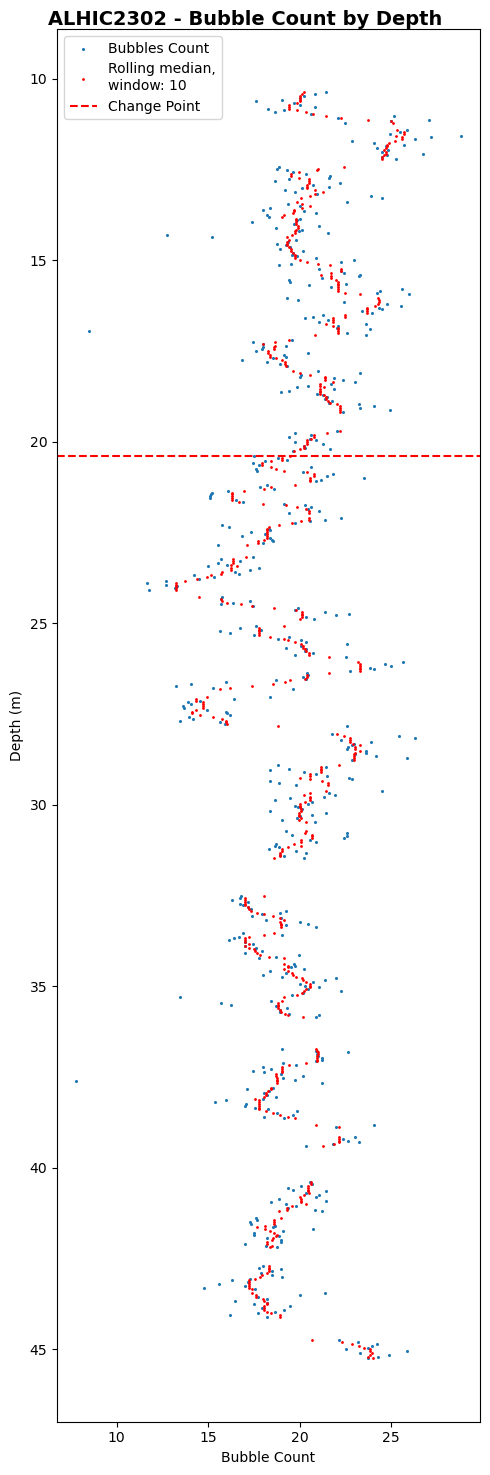

In [10]:
import numpy as np
import pandas as pd
import ruptures as rpt
import matplotlib.pyplot as plt

def overlay_median_line(ax, x_vals: np.ndarray, depths: np.ndarray):
    window_rows = 10
    min_count = 5
    
    med = _rolling_median_rows(
        x_vals.astype(float),
        window_rows=window_rows,
        min_count=min_count
    )
    mask = ~(np.isnan(med) | np.isnan(depths))
    if np.any(mask):
        ax.scatter(med[mask], depths[mask], c='red', s=1, label=f"Rolling median,\nwindow: {window_rows}")

df = bubbles_df

# Extract the signal
signal = df['Bubble_Count'].values  # 1D array for univariate

# Initialize PELT with chosen model
model = "rbf"  # Change as needed: "l1", "rbf", etc.
algo = rpt.Pelt(model=model, min_size=5, jump=5).fit(signal)

# Set penalty 
n = len(signal)
pen = 2 * np.log(n) 

# Detect change points
change_points = algo.predict(pen=pen)

# Print results
print("Detected change points (indices):", change_points[:-1])  # Exclude the last (end of signal)


if 'Depth_cm' in df.columns:
    fig, ax = plt.subplots(figsize=(5, 15))
    depth = df['Depth_cm'].values / 100
    ax.scatter(signal, depth, label='Bubbles Count', s=1.5)  # x='Sums', y='Depth'
    overlay_median_line(ax, signal, depth)
    for cp in change_points[:-1]:
        ax.axhline(y=depth[cp], color='r', linestyle='--', label='Change Point' if cp == change_points[0] else None)
    ax.invert_yaxis()  # If depth increases downward
    ax.set_xlabel('Bubble Count')
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.set_ylabel('Depth (m)')
    ax.legend()

    # Title & save/show
    fig.suptitle("ALHIC2302 - Bubble Count by Depth", fontsize=14, fontweight='bold')
    fig.tight_layout()

    out_path = output_dir
    fname = "bubbles_cpd"
    out_path = (out_path / f"{fname}.png")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

Detected change points (indices): [290, 350, 420]
Detected change points (depth): [np.int64(2713), np.int64(3072), np.int64(3550)]


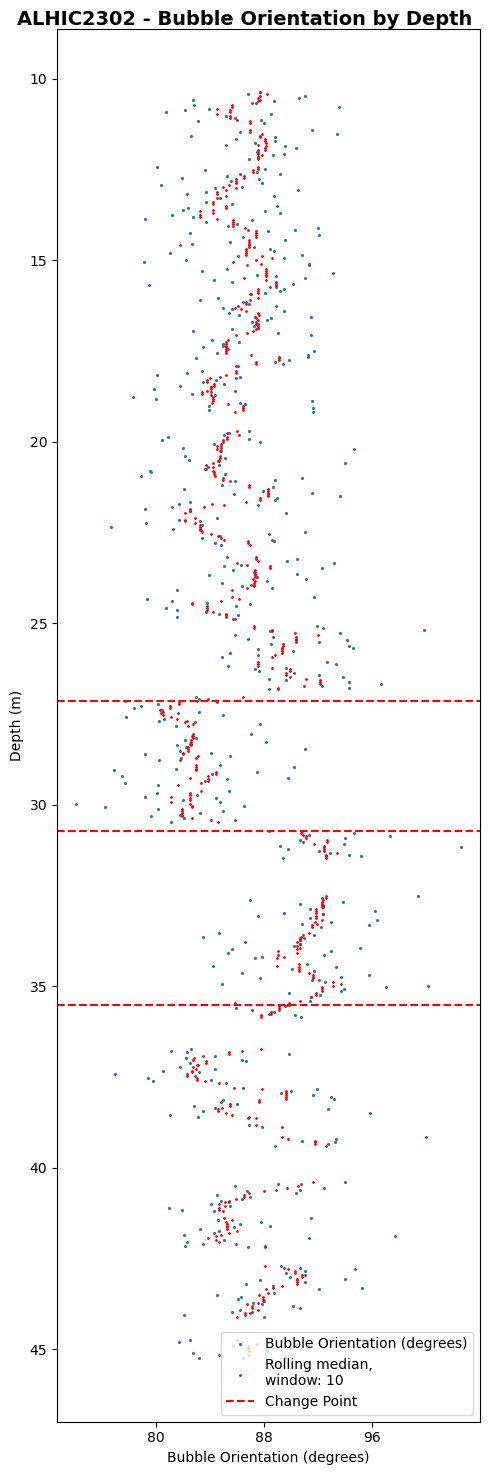

In [11]:
# Extract the signal (must be a NumPy array)
signal = df['Avg_Orientation'].values  # 1D array for univariate

# Initialize PELT with chosen model
model = "rbf"  # Change as needed: "l1", "rbf", etc.
algo = rpt.Pelt(model=model, min_size=5, jump=10).fit(signal)

# Set penalty (adjust based on data size and desired sensitivity)
n = len(signal)
pen = 1 * np.log(n)  # Starting suggestion; tune up/down

# Detect change points
change_points = algo.predict(pen=pen)

# Print results (indices in the array/DataFrame)
print("Detected change points (indices):", change_points[:-1])  # Exclude the last (end of signal)
cp = []
for i in change_points[:-1]:
    cp.append(df.loc[i, "Depth_cm"])
print("Detected change points (depth):", cp)

# Or custom plot with 'Depth' on y-axis (assuming 'Depth' increases downward)
if 'Depth_cm' in df.columns:
    fig, ax = plt.subplots(figsize=(5, 15))
    depth = df['Depth_cm'].values / 100
    ax.scatter(signal, depth, label='Bubble Orientation (degrees)', s=1.5)  # x='signal', y='Depth'
    overlay_median_line(ax, signal, depth)
    for cp in change_points[:-1]:
        ax.axhline(y=depth[cp], color='r', linestyle='--', label='Change Point' if cp == change_points[0] else None)
    ax.invert_yaxis()  # If depth increases downward
    ax.set_xlabel('Bubble Orientation (degrees)')
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.set_ylabel('Depth (m)')
    ax.legend()

    # Title & save/show
    fig.suptitle("ALHIC2302 - Bubble Orientation by Depth", fontsize=14, fontweight='bold')
    fig.tight_layout()

    out_path = output_dir
    fname = "bubbleAngle_cpd"
    out_path = (out_path / f"{fname}.png")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

Detected change points (indices): [190, 420]


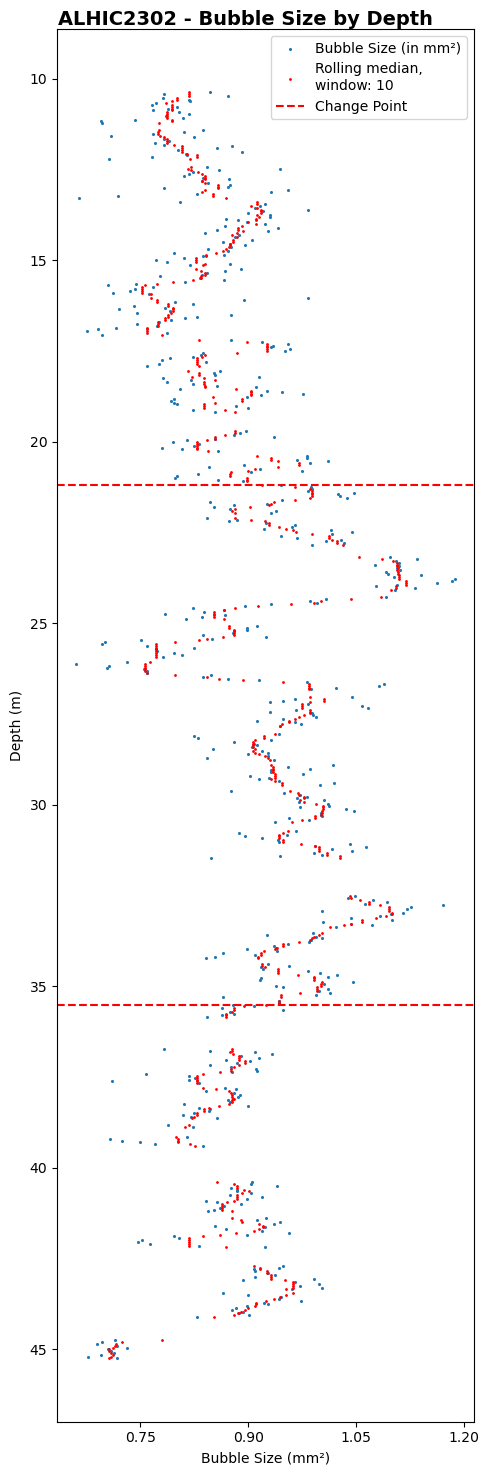

In [12]:
# Extract the signal (must be a NumPy array)
signal = df['Avg_Bubble_Size'].values  # 1D array for univariate

# Initialize PELT with chosen model
model = "rbf"  # Change as needed: "l1", "rbf", etc.
algo = rpt.Pelt(model=model, min_size=5, jump=10).fit(signal)

# Set penalty (adjust based on data size and desired sensitivity)
n = len(signal)
pen = 2 * np.log(n)  # Starting suggestion; tune up/down

# Detect change points
change_points = algo.predict(pen=pen)

# Print results (indices in the array/DataFrame)
print("Detected change points (indices):", change_points[:-1])  # Exclude the last (end of signal)


# Or custom plot with 'Depth' on y-axis (assuming 'Depth' increases downward)
if 'Depth_cm' in df.columns:
    fig, ax = plt.subplots(figsize=(5, 15))
    depth = df['Depth_cm'].values / 100
    ax.scatter(signal, depth, label='Bubble Size (in mm²)', s=1.5)  # x='signal', y='Depth'
    overlay_median_line(ax, signal, depth)
    for cp in change_points[:-1]:
        ax.axhline(y=depth[cp], color='r', linestyle='--', label='Change Point' if cp == change_points[0] else None)
    ax.invert_yaxis()  # If depth increases downward
    ax.set_xlabel('Bubble Size (mm²)')
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.set_ylabel('Depth (m)')
    ax.legend()

    # Title & save/show
    fig.suptitle("ALHIC2302 - Bubble Size by Depth", fontsize=14, fontweight='bold')
    fig.tight_layout()

    out_path = output_dir
    fname = "bubbleSize_cpd"
    out_path = (out_path / f"{fname}.png")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

In [13]:
import numpy as np
import pandas as pd
import ruptures as rpt
import matplotlib.pyplot as plt

ages = pd.read_csv("/data/icecores/ALHIC2302_Ages.csv")
ages["Top depth"] = pd.to_numeric(ages["Top depth"], errors="coerce")
ages["Bottom depth "] = pd.to_numeric(ages["Bottom depth "], errors="coerce")
ages["Argon age "] = pd.to_numeric(ages["Argon age "], errors="coerce")
# Drop any rows with missing or infinite depths
ages = ages.replace([np.inf, -np.inf], np.nan).dropna(subset=["Top depth", "Bottom depth ", "Argon age "])

def _rolling_median_rows(x: np.ndarray, window_rows: int, min_count: int) -> np.ndarray:
    s = pd.Series(x)
    return s.rolling(window=window_rows, center=True, min_periods=min_count).median().to_numpy()

def overlay_median_line(ax, x_vals: np.ndarray, depths: np.ndarray):
    med = _rolling_median_rows(x_vals.astype(float), window_rows=10, min_count=5)
    mask = ~(np.isnan(med) | np.isnan(depths))
    if np.any(mask):
        ax.scatter(med[mask], depths[mask], c='red', s=4, label="Rolling median")

def detect_change_points(signal: np.ndarray, model: str = "rbf",
                         min_size: int = 5, jump: int = 10, pen_scale: float = 2.0):
    algo = rpt.Pelt(model=model, min_size=min_size, jump=jump).fit(signal)
    n = len(signal)
    pen = pen_scale * np.log(n if n > 1 else 2)
    cps = algo.predict(pen=pen)
    return cps[:-1]  # drop last (end marker)

def plot_bubble_cpd(df: pd.DataFrame, output_dir, include_orientation: bool = True):
    depth = df['Depth_cm'].values / 100
    

    panels = [
        ("Bubbles > .5mm²", "Bubble_Count", 3.0, "Bubbles per cm²", None, None, None),
        ("Median Bubble Size", "Median_Bubble_Size", 2.0, "mm²", "STD_Bubble_Size", "Median5_Bubble_Size", "Median95_Bubble_Size"),
        ("Median Bubble Elongation", "Median_Elongation", 2.0, "pxs/pxs", "STD_Elongation", "Median5_Elongation", "Median95_Elongation")
    ]
    if include_orientation and ("Median_Orientation" in df.columns):
        panels.insert(3, ("Median Bubble Orientation", "Median_Orientation", 1.0, "Degrees", "STD_Orientation", "Median5_Orientation", "Median95_Orientation"))

    ncols = len(panels)
    fig, axes = plt.subplots(ncols=ncols, figsize=(5*ncols, 15), sharey=True)
    if ncols == 1:
        axes = [axes]  # normalize to iterable

    fig.suptitle("ALHIC 2302", fontsize=18, fontweight='bold')

    for ax, (title, col, pen_scale, xLabel, std_col, med5, med95) in zip(axes, panels):
        signal = df[col].values.astype(float)
        cps = detect_change_points(signal, pen_scale=pen_scale)
        if med5 != None:
            x_low = (df[col] - df[med5]).to_numpy()
            x_high = (df[med95] - df[col]).to_numpy()
            # Gray 5–95% error bars
            ax.errorbar(
                signal,
                depth,
                xerr=[x_low, x_high],
                fmt='.',
                markersize=7,
                ecolor="lightgray",
                elinewidth=1,
                capsize=0,
                color="tab:blue",
                label="Median (with 5–95%)"
            )
        ax.scatter(signal, depth, s=4.5)
        # if std_col != None:
        #     std = df[std_col].values.astype(float)
        #     ax.scatter(signal, depth, s=4.5+std, facecolor=(1, 1, 1, 0), edgecolors=(0, 0, 0, 1), linewidths=2)
        overlay_median_line(ax, signal, depth)
        for i, cp in enumerate(cps):
            ax.axhline(y=depth[cp], color='r', linestyle='--',
                       label='Change Point' if i == 0 else None)
        for index, row in ages.iterrows():
            top, bottom, age = row["Top depth"], row["Bottom depth "], row["Argon age "]
            # Draw a shaded rectangle for the interval
            ax.axhspan(top, bottom, color="y", alpha=0.3)
            # Label the age in the middle of the interval
            mid_depth = (top + bottom) / 2
            if index % 2 != 1:
                ax.text(ax.get_xlim()[1]*0.85, mid_depth, f"{age} ka",
                    va='center', ha='left', fontsize=9, color='black')
            else:
                ax.text(ax.get_xlim()[1]*0.85, mid_depth, f"{age} ka",
                    va='center', ha='right', fontsize=9, color='black')
        ax.set_title(title, fontweight='bold',  fontsize=15)
        ax.set_xlabel(xLabel, fontsize=14)
        ax.xaxis.set_major_locator(plt.MaxNLocator(5))
        ax.tick_params(axis='x', labelsize=12)
        ax.invert_yaxis()
        # ax.legend(loc="upper center", bbox_to_anchor=(.5,-.1), ncols=2, fontsize=12)

    axes[0].set_ylabel("Depth (m)",  fontsize=14)
    axes[0].tick_params(axis='y', labelsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    if ncols == 4:
        ax.invert_yaxis()

    handles = []
    labels = []
    
    for ax in fig.axes:
        h, l = ax.get_legend_handles_labels()
        handles.extend(h)
        labels.extend(l)
    
    unique = dict(zip(labels, handles))  # label → handle
    
    fig.legend(
        unique.values(),
        unique.keys(),
        loc="upper center",
        bbox_to_anchor=(.5, -0.02),
        ncols=3,
        fontsize=12
    )

    suffix = "" if include_orientation else "_no_orientation"
    out_path = output_dir / f"bubble_combinedMedOverlayCPD{suffix}.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

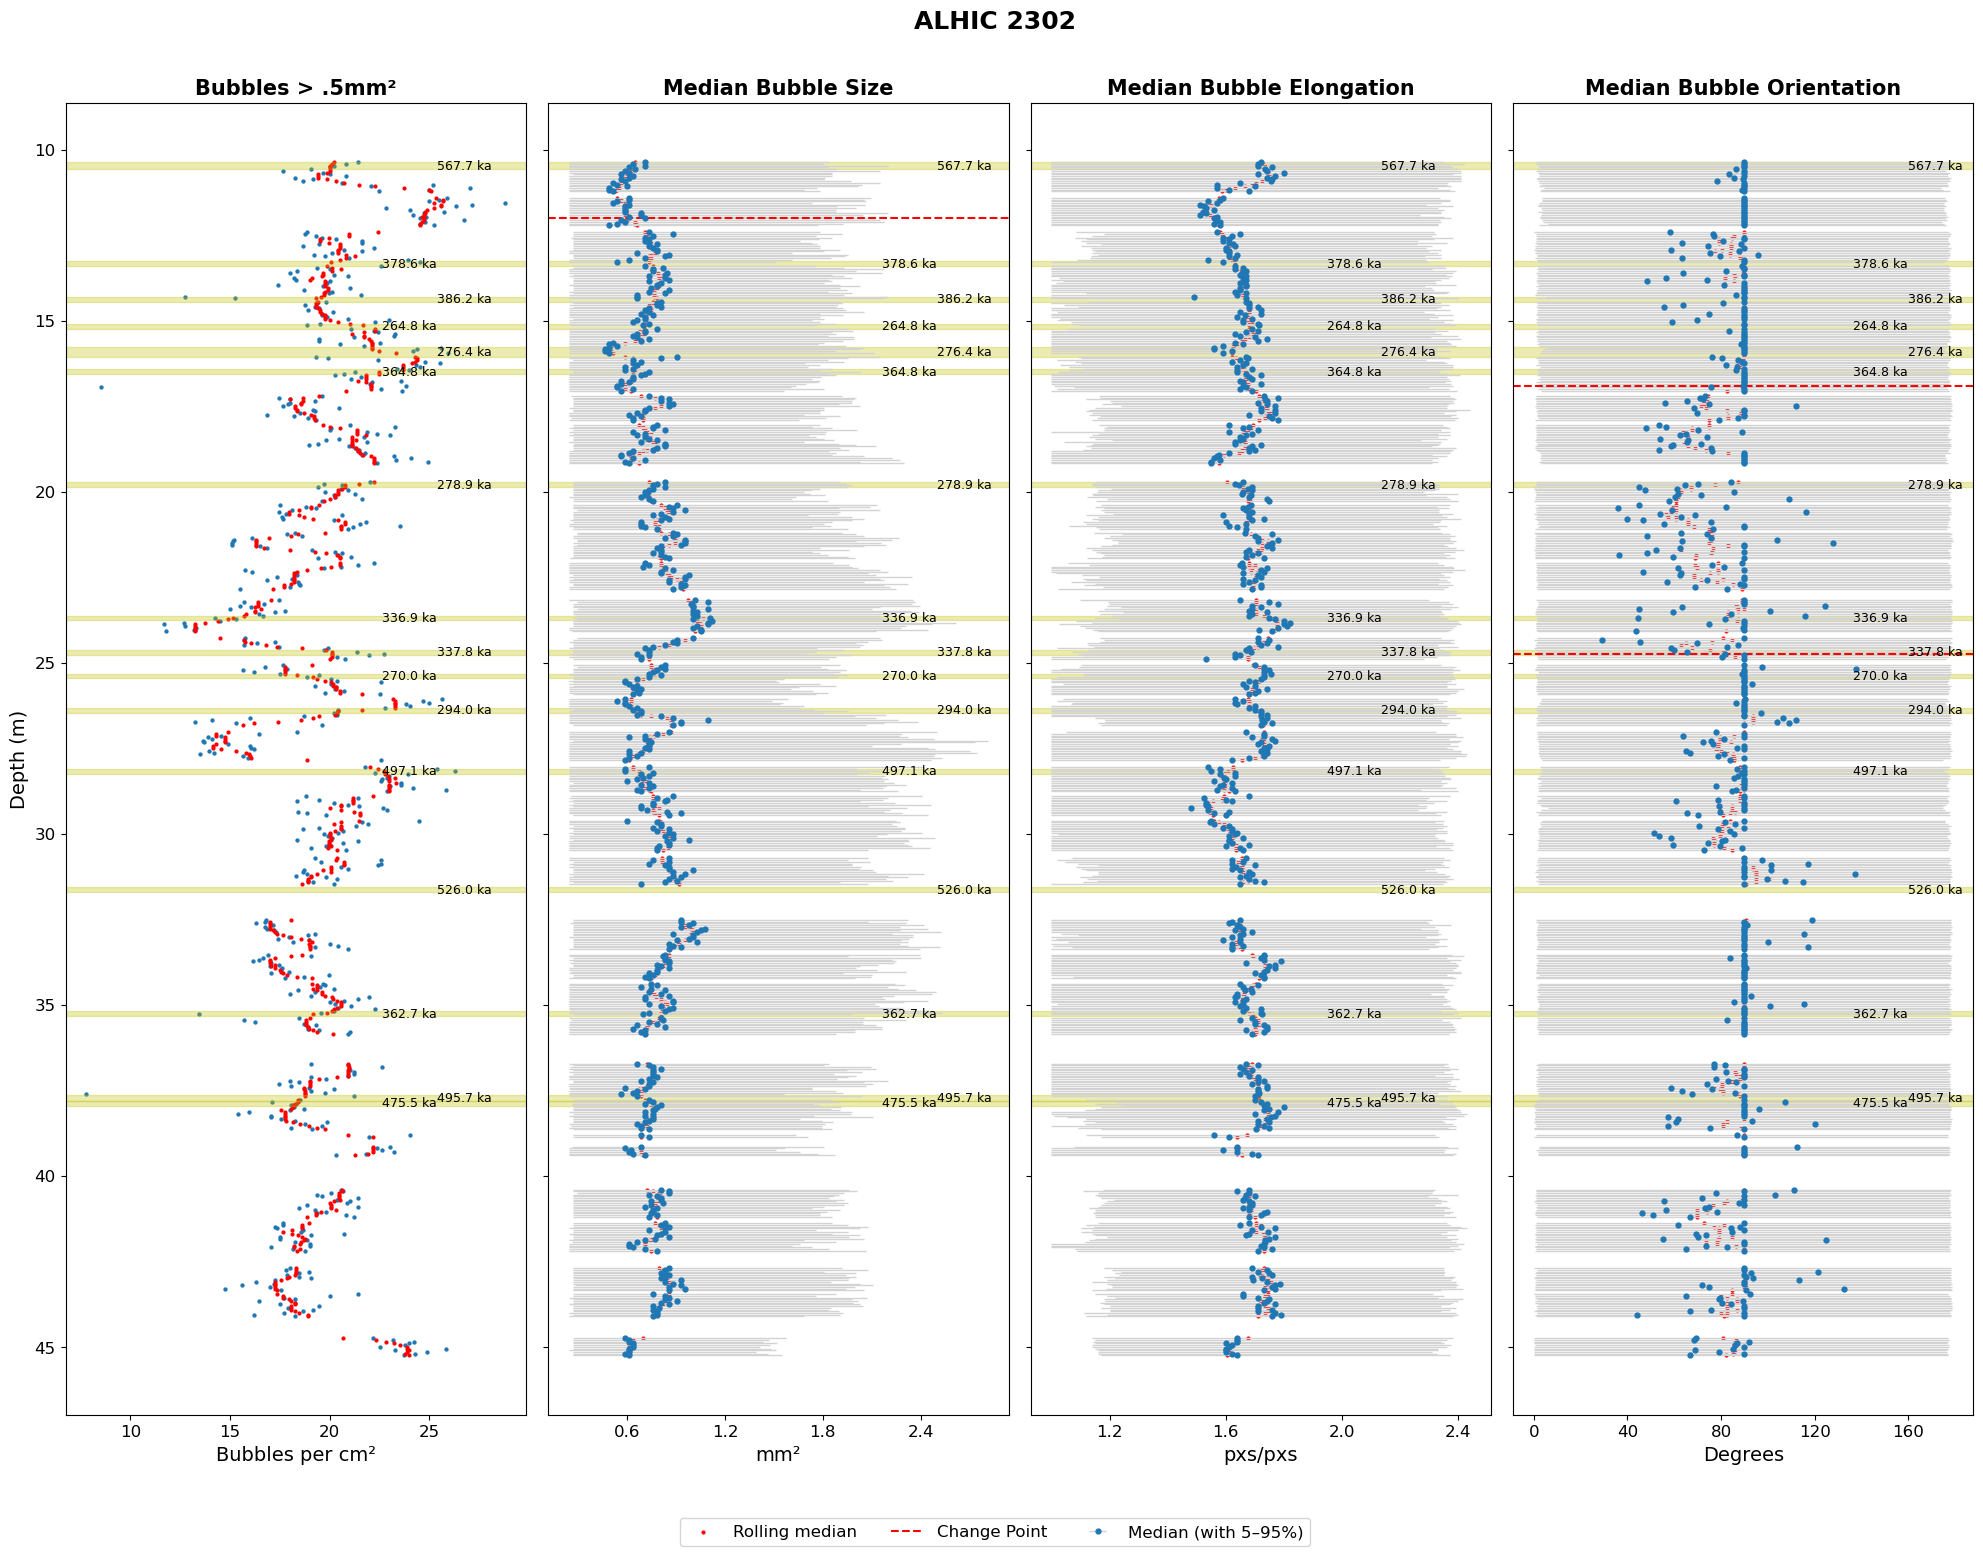

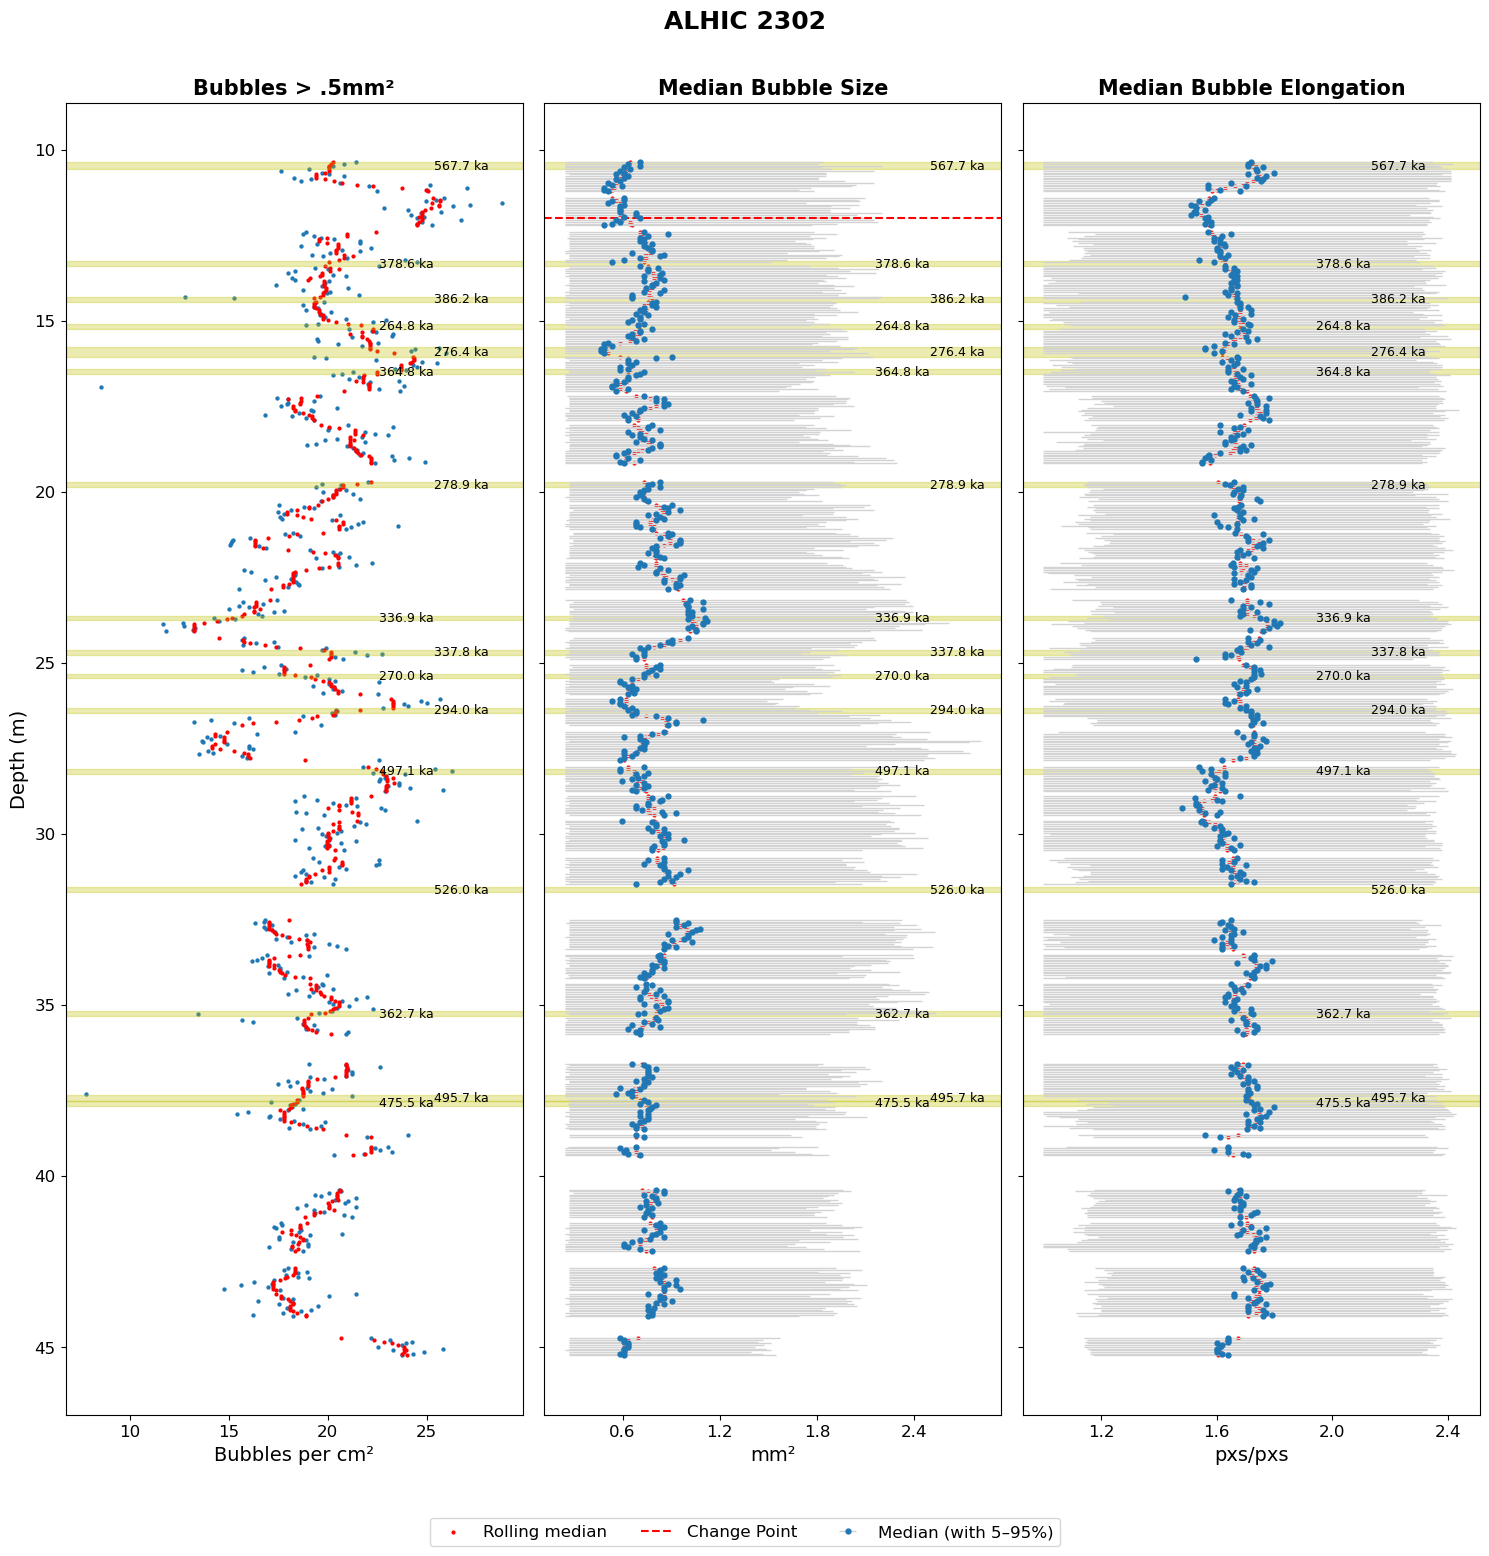

In [14]:
# bubbles_df["Bubble_Count"] = bubbles_df['Bubble_Count'] / 25

plot_bubble_cpd(bubbles_df, output_dir)                  # includes orientation
plot_bubble_cpd(bubbles_df, output_dir, include_orientation=False)  # skips it

In [15]:
import numpy as np
import pandas as pd
import ruptures as rpt
import matplotlib.pyplot as plt

def _rolling_median_rows(x: np.ndarray, window_rows: int, min_count: int) -> np.ndarray:
    s = pd.Series(x)
    return s.rolling(window=window_rows, center=True, min_periods=min_count).median().to_numpy()

def overlay_median_line(ax, x_vals: np.ndarray, depths: np.ndarray):
    med = _rolling_median_rows(x_vals.astype(float), window_rows=10, min_count=5)
    mask = ~(np.isnan(med) | np.isnan(depths))
    if np.any(mask):
        ax.scatter(med[mask], depths[mask], c='red', s=4, label="Rolling median")

def detect_change_points(signal: np.ndarray, model: str = "rbf",
                         min_size: int = 5, jump: int = 10, pen_scale: float = 2.0):
    algo = rpt.Pelt(model=model, min_size=min_size, jump=jump).fit(signal)
    n = len(signal)
    pen = pen_scale * np.log(n if n > 1 else 2)
    cps = algo.predict(pen=pen)
    return cps[:-1]  # drop last (end marker)

def plot_avg_bubble_cpd(df: pd.DataFrame, output_dir, include_orientation: bool = True):
    depth = df['Depth_cm'].values / 100
    

    panels = [
        ("Bubbles > .5mm²", "Bubble_Count", 3.0, "Bubbles per cm²", None),
        ("Average Bubble Size", "Avg_Bubble_Size", 2.0, "mm²", "STD_Bubble_Size"),
        ("Average Bubble Elongation", "Avg_Elongation", 2.0, "pxs/pxs", "STD_Elongation")
    ]
    if include_orientation and ("Avg_Orientation" in df.columns):
        panels.insert(3, ("Average Bubble Orientation", "Avg_Orientation", 1.0, "Degrees", "STD_Orientation"))

    ncols = len(panels)
    fig, axes = plt.subplots(ncols=ncols, figsize=(5*ncols, 15), sharey=True)
    if ncols == 1:
        axes = [axes]  # normalize to iterable

    fig.suptitle("ALHIC2302 - Bubble Properties by Depth", fontsize=18, fontweight='bold')

    for ax, (title, col, pen_scale, xLabel, std_col) in zip(axes, panels):
        signal = df[col].values.astype(float)
        cps = detect_change_points(signal, pen_scale=pen_scale)
        if std_col != None:
            x = signal
            std = df[std_col].to_numpy()
            ax.errorbar(
                x,
                depth,
                xerr=std,
                fmt='.',
                markersize=1.5,
                ecolor="lightgray",
                elinewidth=0.8,
                capsize=0,
                color="tab:blue",
                label="±1σ"
            )
        ax.scatter(signal, depth, s=4.5)
        for index, row in ages.iterrows():
            top, bottom, age = row["Top depth"], row["Bottom depth "], row["Argon age "]
            # Draw a shaded rectangle for the interval
            ax.axhspan(top, bottom, color="y", alpha=0.3)
            # Label the age in the middle of the interval
            mid_depth = (top + bottom) / 2
            if index % 2 != 1:
                ax.text(ax.get_xlim()[1]*0.85, mid_depth, f"{age} ka",
                    va='center', ha='left', fontsize=9, color='black')
            else:
                ax.text(ax.get_xlim()[1]*0.85, mid_depth, f"{age} ka",
                    va='center', ha='right', fontsize=9, color='black')
        overlay_median_line(ax, signal, depth)
        for i, cp in enumerate(cps):
            ax.axhline(y=depth[cp], color='r', linestyle='--',
                       label='Change Point' if i == 0 else None)
        ax.set_title(title, fontweight='bold',  fontsize=15)
        ax.set_xlabel(xLabel, fontsize=14)
        ax.xaxis.set_major_locator(plt.MaxNLocator(5))
        ax.tick_params(axis='x', labelsize=12)
        ax.invert_yaxis()
        # ax.legend(loc=1, fontsize=12)

    handles = []
    labels = []
    
    for ax in fig.axes:
        h, l = ax.get_legend_handles_labels()
        handles.extend(h)
        labels.extend(l)
    
    unique = dict(zip(labels, handles))  # label → handle
    
    fig.legend(
        unique.values(),
        unique.keys(),
        loc="upper center",
        bbox_to_anchor=(.5, -0.02),
        ncols=3,
        fontsize=12
    )
    axes[0].set_ylabel("Depth (m)",  fontsize=14)
    axes[0].tick_params(axis='y', labelsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    if ncols == 4:
        ax.invert_yaxis()

    suffix = "" if include_orientation else "_no_orientation"
    out_path = output_dir / f"AvgBubble_combinedMedOverlayCPD{suffix}.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

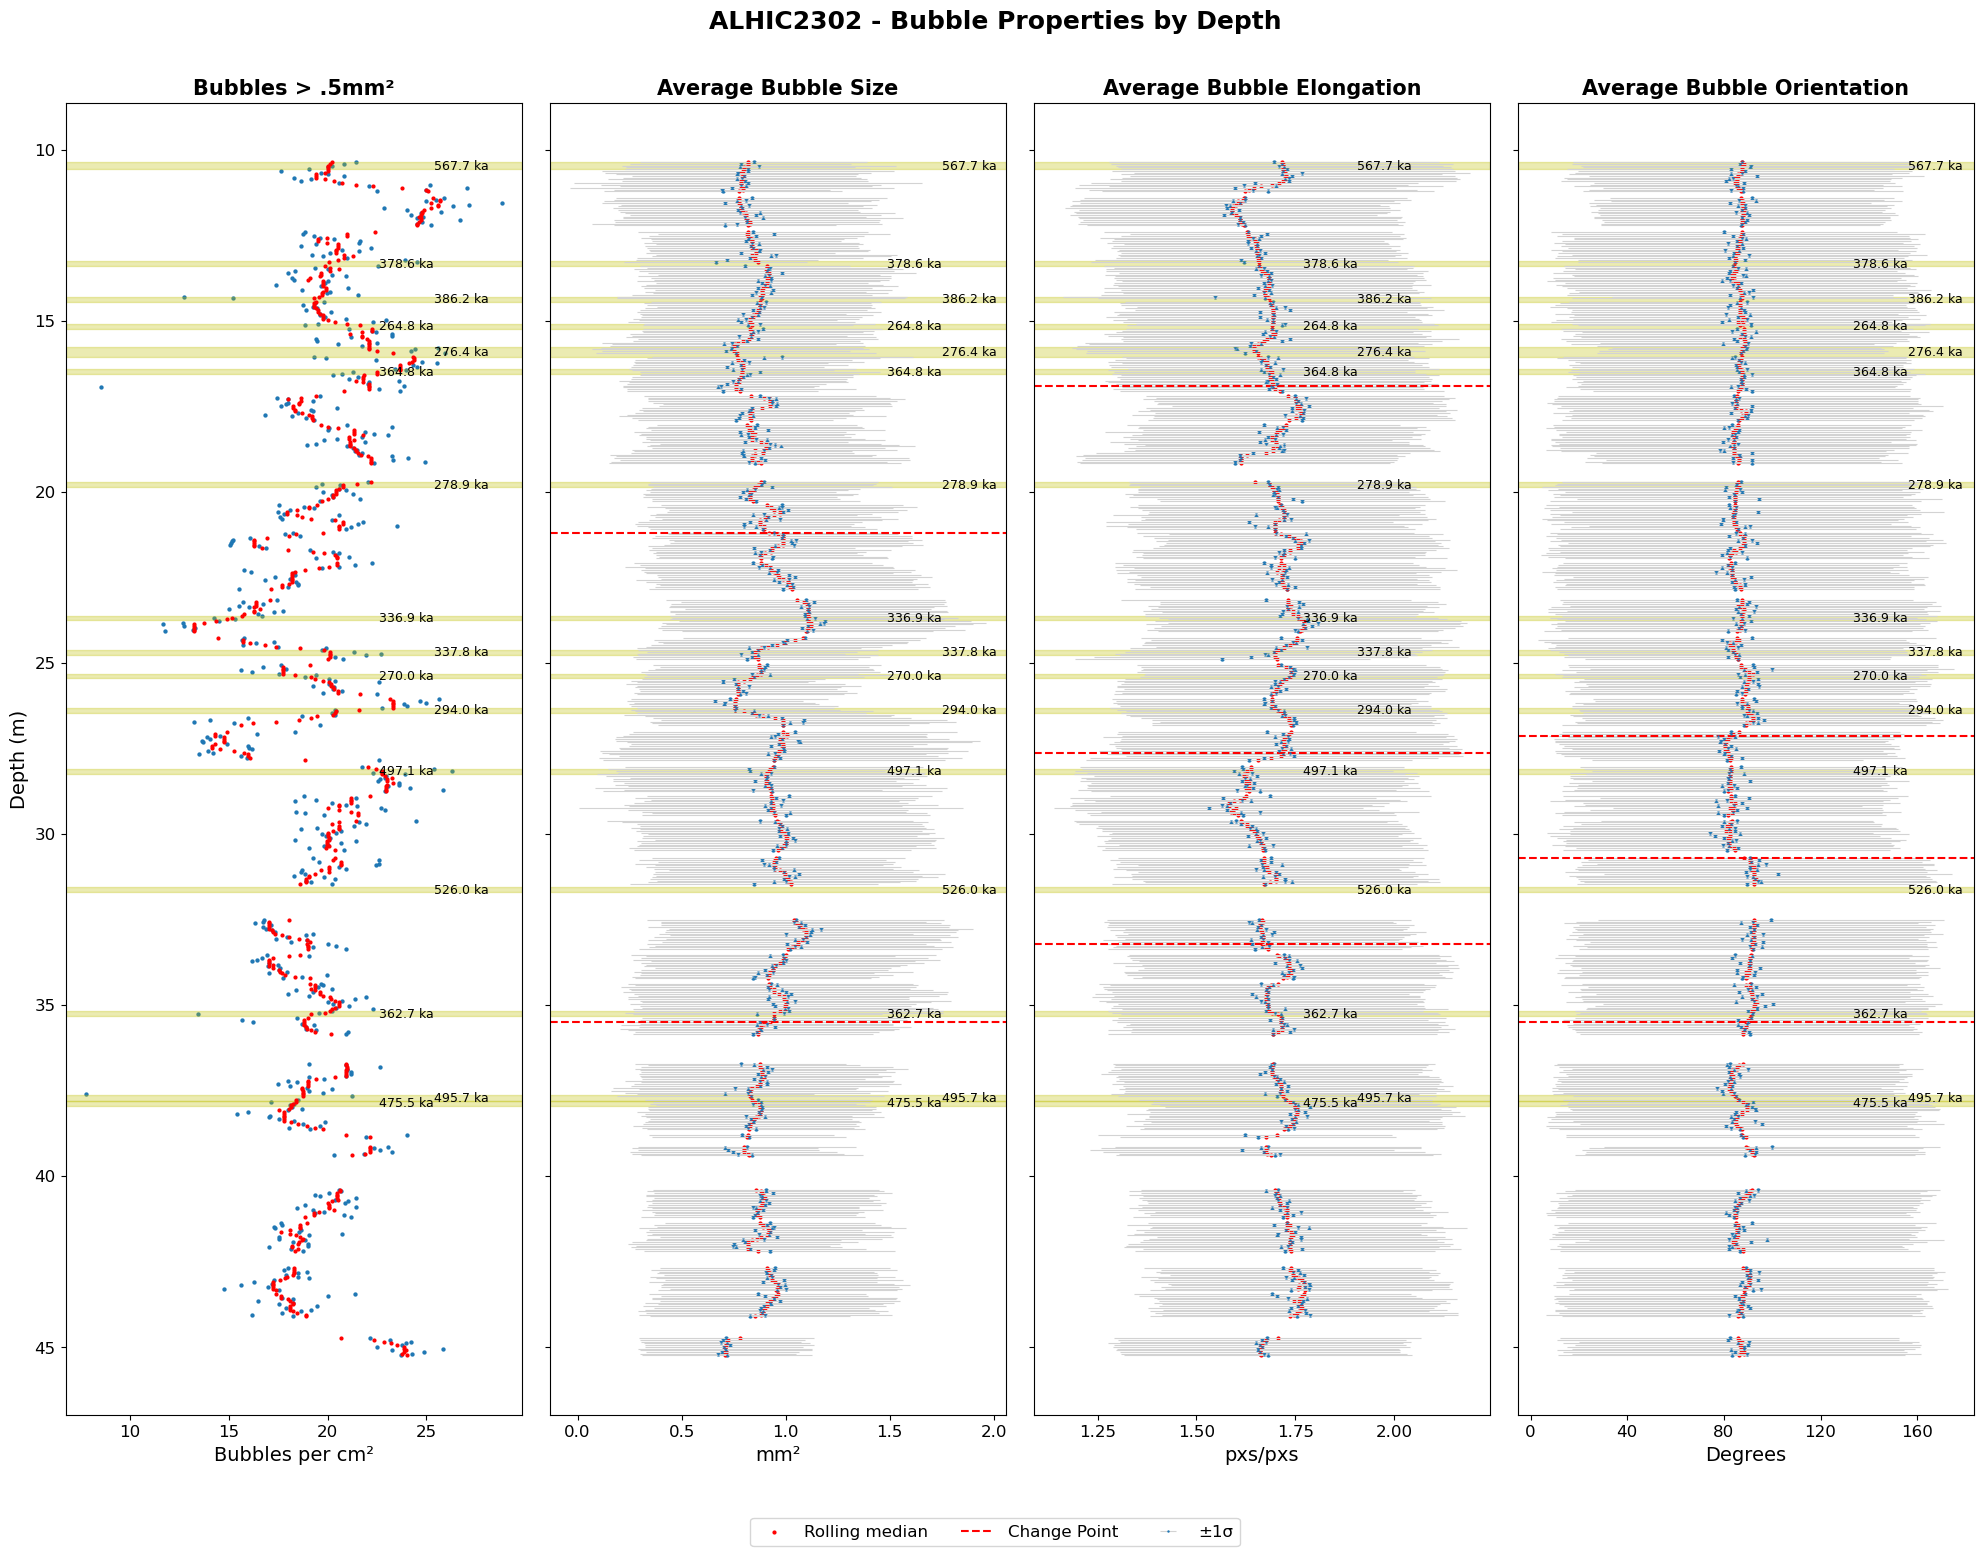

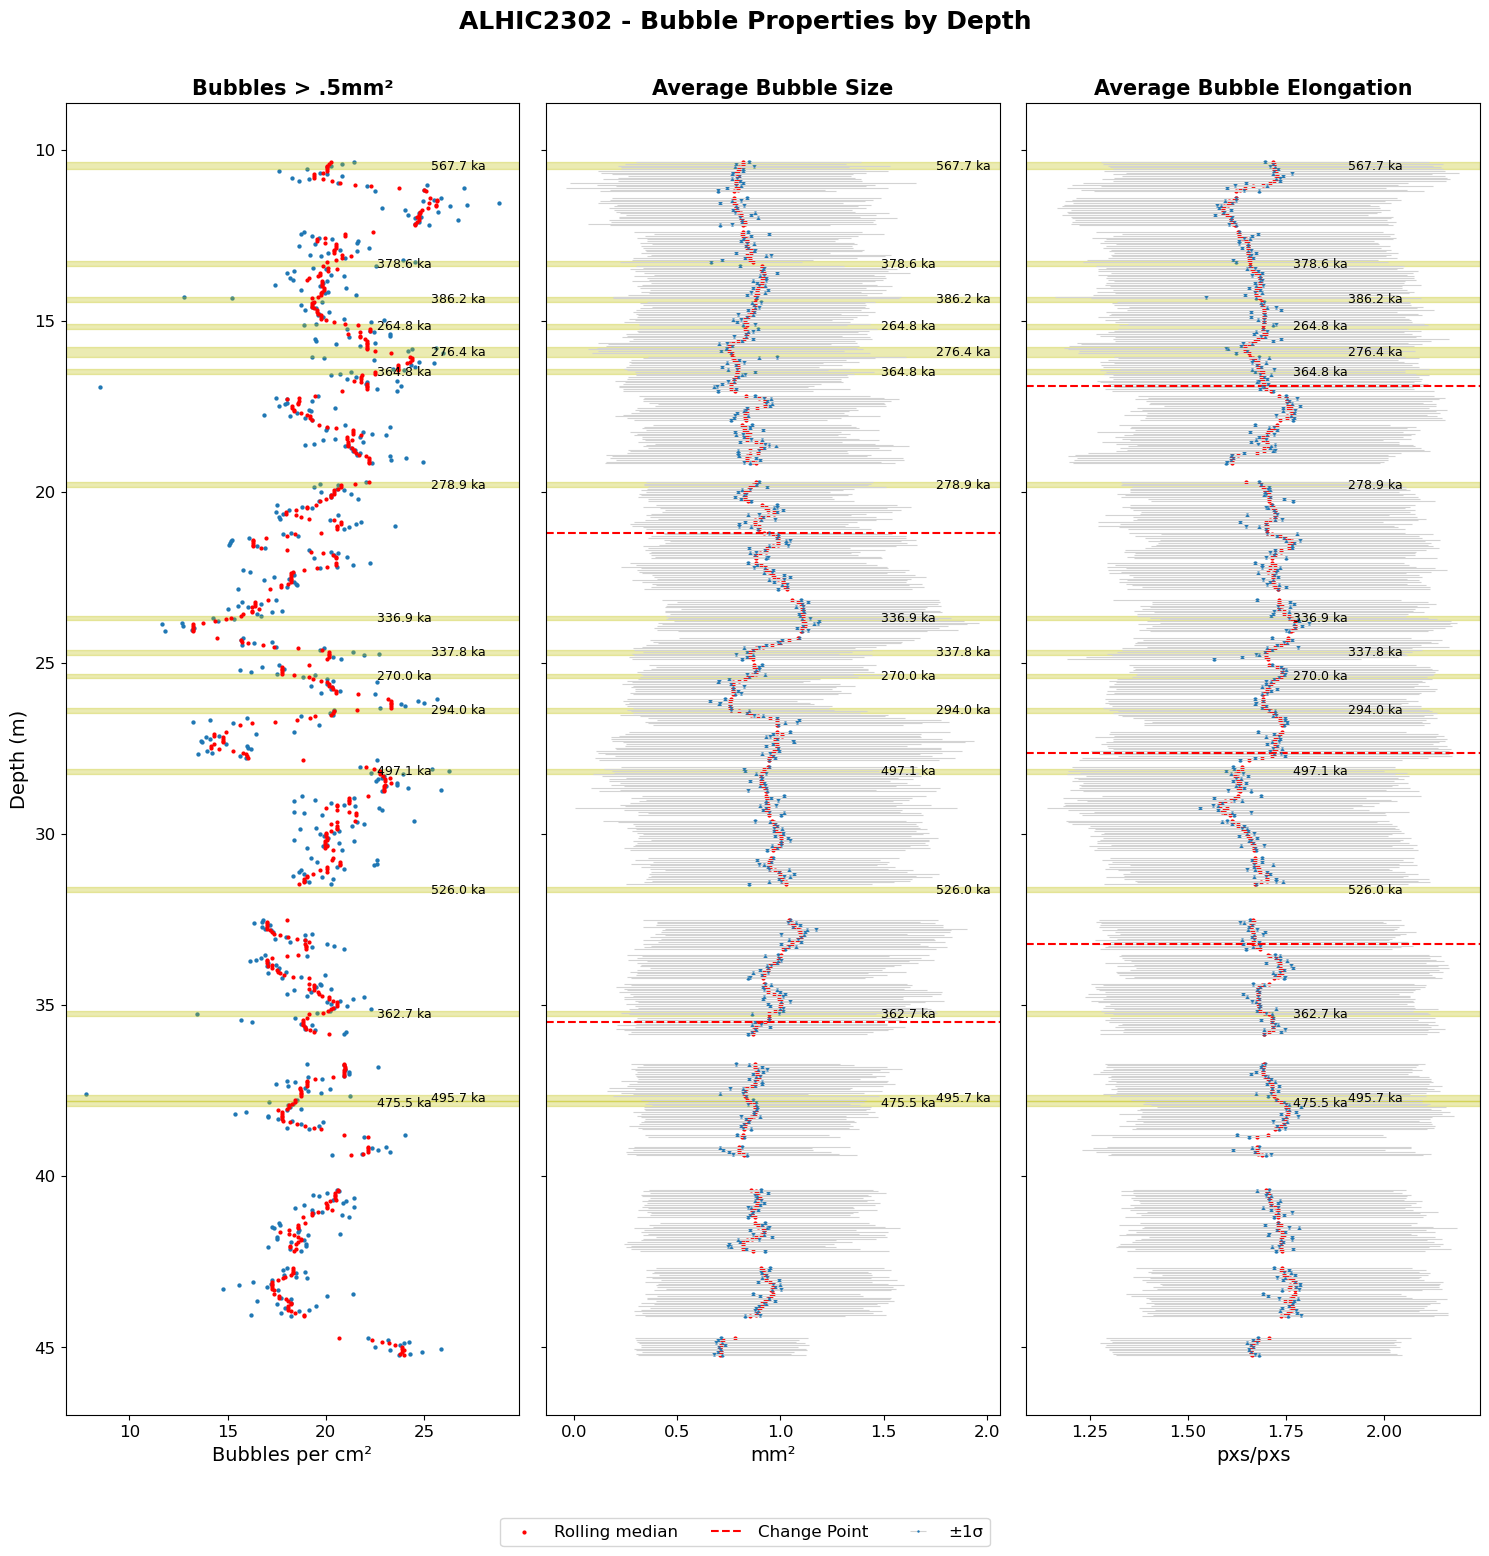

In [16]:
plot_avg_bubble_cpd(bubbles_df, output_dir)                  # includes orientation
plot_avg_bubble_cpd(bubbles_df, output_dir, include_orientation=False)  # skips it

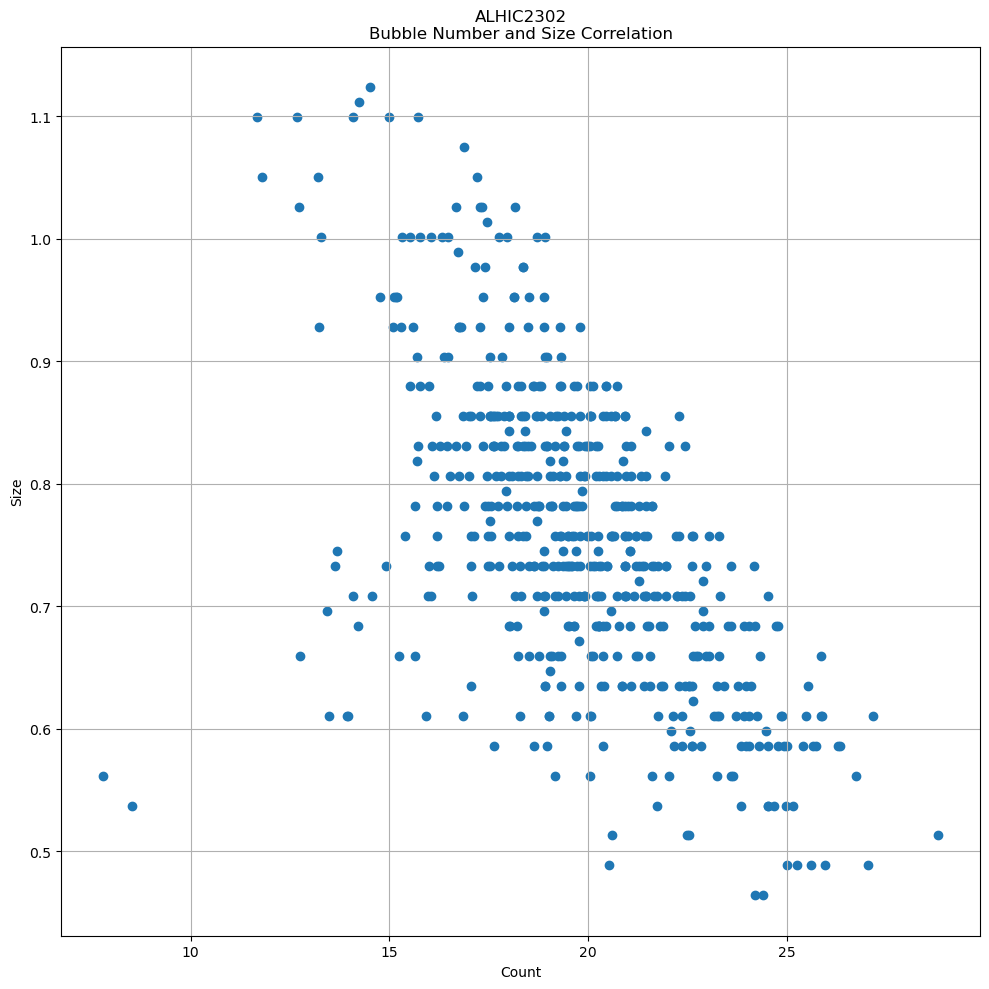

In [17]:
plt.figure(figsize=(10, 10))

plt.scatter(bubbles_df["Bubble_Count"], bubbles_df["Median_Bubble_Size"])

plt.xlabel("Count")
plt.ylabel("Size")
plt.title("ALHIC2302\nBubble Number and Size Correlation")
plt.grid(True)
plt.tight_layout()
outputPath = '/data/icecores/Output/Figures'
out_path = f"{outputPath}/ALHIC2302_BubbleSizeCorrelation.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

In [18]:
from pathlib import Path
from typing import Optional, Dict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def plot_stats_by_depth(df1: pd.DataFrame,
                        df2: pd.DataFrame,
                        save: bool = False,
                        save_path: Optional[Path | str] = None,
                        show: bool = True,
                        invert_depth_axis: bool = True,
                        shade_gaps: bool = False,
                        gap_threshold: float = 2.0,
                        # --- PCA options (runs on df1 by default) ---
                        do_pca: bool = False,
                        pca_n_components: int = 2,
                        standardize: bool = True,
                        # --- legend labels ---
                        label1: str = "Reflectance",
                        label2: str = "Transmissive") -> Dict[str, Optional[Path]]:
    """
    Overlay two datasets (same Depth_cm grid) on a shared y-axis (Depth),
    with dual x-axes (bottom=blue for df1, top=orange for df2).
    Each subplot shows one of: Sums, Medians, Means.
    """

    required = {"Depth_cm", "Sums", "Medians", "Means"}
    for i, (name, df) in enumerate([(label1, df1), (label2, df2)], start=1):
        missing = required.difference(df.columns)
        if missing:
            raise ValueError(f"{name} missing columns: {sorted(missing)}")

    def _clean(df: pd.DataFrame) -> pd.DataFrame:
        d = df.copy()
        d["Depth_cm"] = pd.to_numeric(d["Depth_cm"], errors="coerce")
        # d['Depth_cm'] = d['Depth_cm'] / 100
        d["Sums"] = pd.to_numeric(d["Sums"], errors="coerce")
        d["Medians"] = pd.to_numeric(d["Medians"], errors="coerce")
        d["Means"] = pd.to_numeric(d["Means"], errors="coerce")
        d = d.dropna(subset=["Depth_cm", "Sums", "Medians", "Means"]).sort_values("Depth_cm")
        return d

    d1, d2 = _clean(df1), _clean(df2)

    # BEFORE merge:
    d1["Depth_key"] = d1["Depth_cm"].round(6)
    d2["Depth_key"] = d2["Depth_cm"].round(6)
    
    merged = pd.merge(
        d1, d2,
        on="Depth_key",
        how="inner",
        suffixes=("_1", "_2")
    ).drop(columns=["Depth_key"])
    
    # canonical Depth
    merged["Depth_cm"] = merged["Depth_cm_1"]


    depths = merged["Depth_cm"].to_numpy()

    if save:
        save_dir = Path(save_path) if save_path else Path(".")
        save_dir.mkdir(parents=True, exist_ok=True)
    else:
        save_dir = None

    # ----------- Main Plot -----------
    fig, axes = plt.subplots(1, 3, figsize=(20, 50), sharey=True)

    metrics = [
        ("Cumulative",    merged["Sums_1"],    merged["Sums_2"]),
        ("Medians", merged["Medians_1"], merged["Medians_2"]),
        ("Means",   merged["Means_1"],   merged["Means_2"]),
    ]

    for ax, (label, v1, v2) in zip(axes, metrics):

        # df1 → bottom x-axis
        p1 = ax.scatter(v1, depths, s=2, color="C0", alpha=1, label=label1)
        ax.set_xlabel(f"{label}", fontsize=12)
        ax.tick_params(axis="x")

        # df2 → top x-axis
        p2 = ax.scatter(v2, depths, s=1, color="C1", alpha=.7, label=label2)
        #ax2.set_xlabel(f"{label} ({label2})")
        #ax2.tick_params(axis="x")

        # Optional gap shading
        if shade_gaps:
            gaps = np.where(np.diff(depths) > gap_threshold)[0]
            for g in gaps:
                y1, y2 = depths[g], depths[g + 1]
                ax.axhspan(y1, y2, color="gray", alpha=0.15)

        # Shared styling
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.legend(handles=[p1, p2], labels=[label1, label2],loc=2, markerscale=2, fontsize=12)
        if invert_depth_axis:
            ax.invert_yaxis()
        if ax is axes[0]:
            ax.set_ylabel("Depth (m)", fontsize=12)

    fig.suptitle("ALHIC2302 Pixel Intensity By Depth\n (Transmissive vs. Reflective Lighting)", fontsize=16, fontweight='bold')
    fig.tight_layout(rect=[0, 0, 1, 0.97])

    out_stats = None
    if save:
        out_stats = save_dir / ("stats_by_depth_dualx.png" if not shade_gaps
                                else "stats_by_depth_dualx_shaded.png")
        fig.savefig(out_stats, dpi=300, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    # ----------- Optional PCA on df1 -----------
    out_pca = None
    if do_pca:
        features = ["Sums", "Means", "Medians"]
        X = d1[features].to_numpy()

        max_comps = min(pca_n_components, X.shape[0], X.shape[1])
        if max_comps < 1:
            raise ValueError("Not enough data for PCA on df1.")

        X_proc = StandardScaler().fit_transform(X) if standardize else X
        pca = PCA(n_components=max_comps)
        pcs = pca.fit_transform(X_proc)
        evr = pca.explained_variance_ratio_

        print(f"PCA (df1) explained variance ratio: {np.round(evr, 4)}")

        plt.figure(figsize=(6, 5))
        if max_comps >= 2:
            sc = plt.scatter(pcs[:, 0], pcs[:, 1], c=d1["Depth_cm"], s=10, cmap="viridis")
            plt.colorbar(sc, label="Depth (cm)")
            plt.xlabel("PC1")
            plt.ylabel("PC2")
        else:
            plt.scatter(pcs[:, 0], d1["Depth_cm"], s=10)
            plt.gca().invert_yaxis()
            plt.xlabel("PC1")
            plt.ylabel("Depth (cm)")

        plt.title("PCA of Sums, Means, Medians (df1)")
        plt.grid(alpha=0.3)

        if save:
            out_pca = save_dir / "pca_df1.png"
            plt.savefig(out_pca, dpi=300, bbox_inches="tight")

        if show:
            plt.show()
        else:
            plt.close()

    return {"stats_by_depth": out_stats, "pca_scatter": out_pca}

In [19]:
results = plot_stats_by_depth(
    combined_df,
    transmissive_df,
    save=True,
    save_path=output_dir,
    show=True,
    invert_depth_axis=True,
    shade_gaps=False,
    gap_threshold=2.0
)

NameError: name 'transmissive_df' is not defined

In [ ]:
signal1 = combined_df["Sums"]
signal2 = transmissive_df["Sums"]

# BEFORE merge:
combined_df["Depth_key"] = combined_df["Depth_cm"].round(6)
transmissive_df["Depth_key"] = transmissive_df["Depth_cm"].round(6)

merged = pd.merge(
    combined_df, transmissive_df,
    on="Depth_key",
    how="inner",
    suffixes=("_1", "_2")
).drop(columns=["Depth_key"])

# canonical Depth
merged["Depth_cm"] = merged["Depth_cm_1"]

plt.figure(figsize=(10, 10))

plt.scatter(merged["Sums_1"], merged["Sums_2"])

plt.xlabel("Transmissive")
plt.ylabel("Reflective")
plt.title("ALHIC2302-29\nPixel Intensity: Correlation")
plt.grid(True)
plt.tight_layout()
outputPath = '/data/icecores/Output/Figures'
out_path = f"{outputPath}/ALHIC2302_CumulativeIntensityCorrelation.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import numpy as np

output_dir = Path("/data/icecores/Output/AN/ALHIC/ALHIC2302/FullCoreData/2025-10-23_215751")

dir_path= "/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-36/2025-10-27_133637"
csv_name = "Sums.csv"
img_name = "row_sums.png"
x_col= "Sums"
y_col= "Depth_cm"

csv_path = Path(str(dir_path + "/" + csv_name))
img_path = Path(str(dir_path + "/" + img_name))

# --- Load data ---
df = pd.read_csv(csv_path).dropna(subset=[y_col, x_col])
df['Depth_cm'] = df['Depth_cm'].values / 100
img = mpimg.imread(img_path)
H, W = img.shape[0], img.shape[1]

# print(f"Image Shape: {img.shape}")
# print(f"CSV Shape: {df.shape}")

# --- Map data -> pixel space of the image ---
x_min, x_max = float(df[x_col].min()), float(df[x_col].max())
y_min, y_max = float(df[y_col].min()), float(df[y_col].max())

def linmap(v, a0, a1, b0, b1):
    return b0 + (np.asarray(v) - a0) * (b1 - b0) / (a1 - a0 + 1e-12)

x_px = df[x_col]
y_px = linmap(df[y_col], y_min, y_max, 0, H)

# --- Plot ---
fig, ax = plt.subplots(figsize=(6, 10))
ax.imshow(img, extent=[x_min, x_max, H, 0], aspect="auto", interpolation="nearest", zorder=1)

ax.scatter(x_px, y_px, s=1, c="red", alpha=0.8, zorder=2)

# --- Set y-axis ticks in real depth units ---
n_ticks = 10
pixel_ticks = np.linspace(0, H, n_ticks)
depth_labels = np.linspace(y_min, y_max, n_ticks)
ax.set_yticks(pixel_ticks)
ax.set_yticklabels([f"{d:.1f}" for d in depth_labels])

ax.set_xlabel('Pixel Intensity')
ax.set_ylabel("Depth (m)")
ax.set_title("ALHIC2302-36 Reflecting Light\nIntensity by Depth on Px Row Cumulative Intensity Image")
plt.tight_layout()
out_path = output_dir / f"HSIUM-81_IntensityByDepthOverlay.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()